# From BTE to MS-BTE: Confinement, Subbands, and Current

Requires Python 3.9+ and NumPy. Run cells in order. Figures are embedded; browser labs link to the article. The exercise starter and reference solution have different names, so Run All does not overwrite your answer.

[Read in Korean](https://pilkwangkim.github.io/posts/Multi-Subband-Boltzmann-Transport-From-Scratch-KR/) · [Python reference](https://pilkwangkim.github.io/assets/code/multi-subband-bte.py)

Knowing an electron's allowed energies does not tell us the electric current. We must also know which states are occupied, how their occupants move, and how collisions redistribute them. The **Boltzmann transport equation (BTE)** balances these changes.

In a narrow wire, motion across the wire is quantized. The transverse quantum states supply a discrete mode label, while motion along the wire can often still be described by a position and a wavevector. Applying Boltzmann kinetics to those states gives the **multi-subband Boltzmann transport equation (MS-BTE)**. It is a confined-system formulation within the Boltzmann framework, not a separate theory that replaces BTE. [Noei et al., Sec. 2](https://link.springer.com/article/10.1007/s10825-020-01488-4)

There are two different questions: **which physical information must be retained, and how can the resulting equations be solved affordably?** A change of basis, a physical approximation, and a numerical truncation answer different parts of those questions. Keeping them separate explains both the usefulness and the limits of MS-BTE.

## 1. BTE balances motion and collisions

First consider transport along one coordinate $x$. Write $f(x,k,t)$ for the dimensionless occupation **per spin** of a local electron state near position $x$ and wavevector $k$ at time $t$. For fermions, $0\le f\le1$. In this statistical description, occupation 0.3 means that state is occupied with probability 0.3, not that 30% of all electrons in the device are there. Summing occupations over available states counts particles; the occupations are not normalized to sum to one.

Position and momentum together form **phase space**; here the momentum variable is $\hbar k$. These labels resolve local wavepackets or neighborhoods of states, not simultaneous exact position and momentum eigenvalues. A **semiclassical** description uses quantum energies and scattering probabilities but follows the approximate motion of packet centres between collisions. A wavepacket must be sufficiently localized compared with the scale of potential variation; its position and momentum spreads still obey the uncertainty relation. [Xiao, Chang, and Niu, Secs. IV–V](https://doi.org/10.1103/RevModPhys.82.1959)

If a packet moves with velocity $v$ and experiences force $F$, then $\dot x=v$ and $\hbar\dot k=F$. The simplest one-dimensional BTE is

$$
\underbrace{\partial_t f}_{\text{local change}}
+\underbrace{v\partial_x f}_{\text{motion in position}}
+\underbrace{\frac{F}{\hbar}\partial_k f}_{\text{motion in momentum}}
=\underbrace{C[f]}_{\text{collisions}}.
\tag{1}
$$

Each term has units of inverse time. A collision term is a rate of change of occupation, not a force and not necessarily a loss of particles. For example, take **elastic** (energy-conserving) exchange between two equally weighted states, with the same unblocked coefficient $r$ in both directions—**reciprocal** exchange. The first state's net change is $r(f_2-f_1)$. The individual gain and loss include Pauli blocking; their cancellation in this net expression, and unequal state-counting weights, will be treated explicitly when constructing the collision model.

The left side is a derivative **along a trajectory**, written using derivatives at fixed $x,k$. With no collisions, an occupation profile is carried along trajectories. At a fixed location, however, the occupation may change as different parts of that profile pass by. A **stationary** solution sets $\partial_t f=0$; it need not have zero velocity or zero current.



**Derivation: why motion produces two derivative terms**


During collisionless motion, occupation stays constant along the electron's trajectory. Over a short interval $dt$, the first-order displacement is $(\dot x\,dt,\dot k\,dt)$, so

$$
f(x+\dot x\,dt,k+\dot k\,dt,t+dt)=f(x,k,t)+\mathcal O(dt^2).
\tag{2}
$$

Taylor-expand the left side to first order, subtract $f(x,k,t)$, divide by $dt$, and take $dt\to0$. This gives $\partial_t f+\dot x\,\partial_x f+\dot k\,\partial_k f=0$. Adding the collision-induced rate gives Eq. (1). It is the chain rule, not an extra source of electrons.



BTE is not exact quantum dynamics with a different notation. Its validity depends on the chosen states, semiclassical propagation, and the collision approximation. Solving it with negligible numerical error does not restore quantum information that its model omitted. Conversely, the word “Boltzmann” does not require bulk plane-wave states: quantum-confined states can supply the energies and transition rates. [Milovanović, Sec. 4.2](https://www.iue.tuwien.ac.at/phd/milovanovic/diss_htmlse9.html)

## 2. Two BTE solutions that can be checked by hand

The editable snippets require Python 3.9+ and NumPy; install NumPy with `python3 -m pip install numpy` in a Python environment. Run the snippets in order, or use the executable notebook. The browser examples need no Python setup.

### Free flight: a profile moves without changing its shape

Set $F=0$ and $C=0$, and examine a slice at one fixed $k$, hence one fixed velocity. If the initial profile is $g(x)$, then

$$
f(x,k,t)=g(x-vt),\qquad
\partial_t f=-v g'(x-vt),\quad
v\partial_x f=v g'(x-vt).
\tag{3}
$$

The two derivatives cancel. This example concerns an **occupation profile**, not the modulus squared of a single-electron wavefunction. Use $v=20\,\mathrm{nm/ps}$ and $g(x)=0.1+0.8\exp[-(x+30)^2/(2\times12^2)]$, with $x$ in nanometres. A picosecond is $10^{-12}$ seconds. The peak moves from $-30$ to $-10$ to $10\,\mathrm{nm}$ at $t=0,1,2\,\mathrm{ps}$; its height stays 0.9. No contact or wall is present in this free-flight problem.

### Directional relaxation: occupations change without a spatial gradient

Now take a different problem: two spatially uniform, equal-energy states with equal speed magnitudes and opposite directions. There is no force, and spatial derivatives vanish. A reciprocal elastic, unblocked reversal-rate coefficient $r$ gives

$$
\begin{aligned}
\frac{df_+}{dt}&=r(f_--f_+),&
\frac{df_-}{dt}&=r(f_+-f_-),\\
\frac{d(f_++f_-)}{dt}&=0,&
\frac{d(f_+-f_-)}{dt}&=-2r(f_+-f_-).
\end{aligned}
\tag{4}
$$

Thus the sum is conserved, while the directional imbalance decays. For $f_+(0)=0.8$ and $f_-(0)=0.2$,

$$
f_\pm(t)=0.5\pm0.3e^{-2rt}.
\tag{5}
$$

With $r=0.4\,\mathrm{ps}^{-1}$, the imbalance decays by a factor $e^{-1}$ in $1/(2r)=1.25\,\mathrm{ps}$. The sum happens to be one because of the chosen initial values, not because all distributions must be normalized that way. Equal state weights make conservation of this sum a particle-conservation check. These two examples isolate different terms of BTE; they are **not** two panels of one spatially varying scattering solution.


In [1]:
import numpy as np

def packet_occupation(x_nm, t_ps):
    # Fixed-k slice: streaming shifts the centre, not the occupation amplitude.
    centre_nm = -30.0 + 20.0 * t_ps
    return 0.1 + 0.8 * np.exp(-(np.asarray(x_nm) - centre_nm)**2 / (2 * 12.0**2))

def relaxing_pair(t_ps, rate_per_ps=0.4):
    # Uniform equal-speed branches: no streaming term or contact boundary data.
    imbalance = 0.6 * np.exp(-2 * rate_per_ps * np.asarray(t_ps))
    return 0.5 + imbalance / 2, 0.5 - imbalance / 2

assert np.isclose(packet_occupation(10.0, 2.0), 0.9)
t = np.linspace(0, 4, 41)
fp, fm = relaxing_pair(t)
assert np.allclose(fp + fm, 1.0)
assert np.allclose(fp - fm, 0.6 * np.exp(-0.8 * t))
print("At 1.25 ps:", np.round(relaxing_pair(1.25), 4))


At 1.25 ps: [0.6104 0.3896]


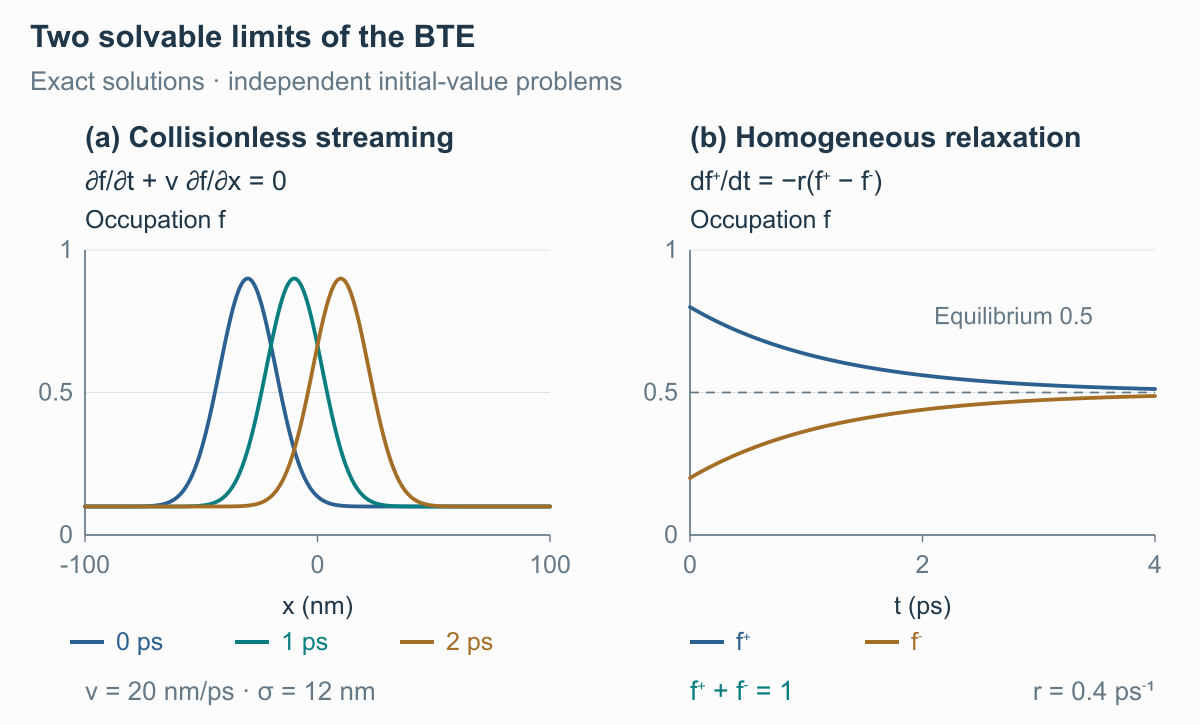

*Figure 1. Free flight translates an occupation profile; reciprocal scattering relaxes a directional imbalance. The left problem has no collisions. The right problem has no spatial gradients. Their separate exact solutions test different parts of a BTE implementation.*



[Open interactive example](https://pilkwangkim.github.io/posts/Multi-Subband-Boltzmann-Transport-From-Scratch/#lab-msbte-basics)


In free-flight mode, change the time and follow the peak. In relaxation mode, compare a zero collision rate with a nonzero rate. Which quantity remains unchanged in each problem?

## 3. Why a direct BTE calculation can become expensive

For a three-dimensional bulk model, the distribution is $f_b(\mathbf r,\mathbf k,t)$: three position coordinates, three wavevector coordinates, time, and a discrete band label $b$. A **band** labels a distinct branch of the material's allowed energy–momentum relation. These are six phase-space variables, plus time, for a **one-particle distribution**, not the $3N$ positions of every electron. For one band, the corresponding equation has the structure

$$
\partial_t f_b+
\mathbf v_b\cdot\nabla_{\mathbf r}f_b+
\frac{\mathbf F_b}{\hbar}\cdot\nabla_{\mathbf k}f_b
=C_b[\lbrace f_{b'}\rbrace].
\tag{6}
$$

The braces indicate that scattering can couple distributions in different bands and at different momenta. **BTE names a kinetic framework, not one prescribed bulk basis or one numerical algorithm.** Deterministic solvers compute distribution values or expansion coefficients directly. Monte Carlo solvers estimate them from sampled trajectories and scattering events. Both can solve Boltzmann models. [Rupp, Grasser, and Jüngel](https://iue.tuwien.ac.at/pdf/ib_2011/BC2012_Rupp_2.pdf)

The storage problem is already visible before assembling a solver. A direct Cartesian grid needs

$$
N_{\rm full}=N_xN_yN_zN_{k_x}N_{k_y}N_{k_z}
\quad\hbox{occupation values per band and time slice}.
\tag{7}
$$

Putting 100 points on each axis gives $10^{12}$ values, or $8\,\mathrm{TB}$ in float64 storage alone, using decimal units. Boundary data, collision coefficients, linear systems, and electrostatics need additional memory and work. This is an illustrative direct-grid count, not a claim that every BTE solver allocates that grid: sampling, symmetry, adaptive resolution, and angular expansions can avoid it. A local collision operator also need not couple every spatial grid point to every other point. [Rupp et al.](https://iue.tuwien.ac.at/pdf/ib_2011/BC2012_Rupp_2.pdf)

For a narrow wire, a different state description may be much more efficient. If a few transverse quantum modes contain the transport-relevant states, replace transverse phase-space resolution by their mode labels. A population model then stores approximately $N_xN_kN_s$ occupations. For $N_x=N_k=100$ and $N_s=10$, that is $10^5$ values, or $0.8\,\mathrm{MB}$:


In [2]:
full_values = 100**6
subband_values = 100 * 100 * 10
print(f"Direct tensor-grid storage: {8 * full_values / 1e12:.1f} TB")
print(f"Ten-mode occupation storage: {8 * subband_values / 1e6:.1f} MB")


Direct tensor-grid storage: 8.0 TB
Ten-mode occupation storage: 0.8 MB


This count compares **representations**, not equal-accuracy simulations or measured speedups. We have not yet justified replacing transverse classical variables by quantum modes, neglecting coherence, or retaining only ten modes. Those are precisely the next questions. A complete all-mode quantum expansion does not by itself throw away information or guarantee a smaller problem.

## 4. A transverse energy level becomes a subband


A bulk semiclassical BTE with continuous transverse momenta and classical wall reflections does not create quantum confinement just because its grid is refined. Classical reflection reverses a velocity component; it does not impose the standing-wave boundary condition of the Schrödinger equation. To capture confinement, the **states and their energies** must already contain that quantum physics.

Take a rectangular wire connected to two large electron reservoirs. The transport direction is $x$, the transverse coordinates are $y,z$, and the contact separation is $L$. In the numerical transport example, its cross-section and prescribed potential energy are constant along $x$. The electrons do not change that potential; their occupations can still vary because of contact injection and scattering.

Use an illustrative **effective mass** $m^*=0.19m_0$ in all directions; $m_0$ is the free-electron mass. There are two spin states with the **same energies and occupations**, with no spin splitting, spin-selective injection, or spin flips. This permits a spin factor of two. The semiconductor model retains one parabolic conduction-band minimum, rather than a complete silicon band structure.

Within an **effective-mass model**, the rapidly varying atomic potential is accounted for through a smooth energy–momentum relation and the parameter $m^{\ast}$. The wavefunction below describes the slowly varying **envelope**, not its additional atomic-scale oscillations inside a crystal. The same $m^{\ast}$ in each direction is the isotropic approximation. For a uniform wire with hard walls at $y=0,W$ and $z=0,H$, the effective Hamiltonian inside the wire is

$$
\widehat H=-\frac{\hbar^2}{2m^*}
\left(\partial_x^2+\partial_y^2+\partial_z^2\right)+U_0.
\tag{8}
$$

$U_0$ is a common potential-energy offset. A hard wall means the wavefunction vanishes at the boundary; the model replaces the surrounding material by an infinite barrier. Write a state as a transverse standing wave times a longitudinal plane wave:

$$
\begin{aligned}
\Psi_{n,k}(x,y,z)&=\phi_n(y,z)\frac{e^{ikx}}{\sqrt{\mathcal L}},\\
\phi_{n_y,n_z}(y,z)&=\frac{2}{\sqrt{WH}}
\sin\!\frac{n_y\pi y}{W}\sin\!\frac{n_z\pi z}{H},\\
n_y,n_z&=1,2,\ldots .
\end{aligned}
\tag{9}
$$

$n=(n_y,n_z)$ labels a transverse mode. The normalization length $\mathcal L$ is used to count longitudinal states; it is not the contact separation $L$. The transverse normalization is $\int_0^W\int_0^H\lvert\phi_n\rvert^2\,dz\,dy=1$.

Substitution into the Schrödinger equation gives

$$
\begin{aligned}
\epsilon_n&=U_0+\frac{\hbar^2\pi^2}{2m^*}
\left(\frac{n_y^2}{W^2}+\frac{n_z^2}{H^2}\right),\\
E_n(k)&=\epsilon_n+\frac{\hbar^2 k^2}{2m^*}.
\end{aligned}
\tag{10}
$$

The **subband edge** $\epsilon_n$ is the minimum energy in that subband, attained at $k=0$. Each transverse level therefore generates a whole parabola, not one isolated total energy. At a given total energy $E>\epsilon_n$, there are two longitudinal states: one with $k>0$ and one with $k<0$.

Separation of variables is exact for this uniform effective Hamiltonian: applying the transverse kinetic-energy operator to $\phi_n$ gives $\epsilon_n-U_0$, while applying the longitudinal part to $e^{ikx}$ gives $\hbar^2k^2/(2m^*)$. Adding them gives Eq. (10). No assumption about how many electrons occupy the states has been made yet.



**What does effective mass retain from the crystal?**


A crystal has ranges of allowed electron energies called **bands**. The conduction band supplies the states used for electron transport in this model. Its energy as a function of crystal wavevector is a **dispersion relation**. Near a smooth minimum $k_0$, a one-dimensional Taylor expansion gives

$$
\begin{aligned}
E_{\rm crystal}(k_0+\delta k)&\simeq E_c+
\frac12 E_{\rm crystal}''(k_0)(\delta k)^2,\\
\frac{1}{m^*}&=\frac{E_{\rm crystal}''(k_0)}{\hbar^2}.
\end{aligned}
$$

$E_c$ is the energy at the minimum, and $\delta k$ is the displacement from it. The first derivative vanishes at a minimum. Fitting this curvature therefore produces a free-particle-like kinetic energy with a different mass parameter. A parabolic approximation is useful near that minimum; it need not describe the entire band. [Purdue NEMO: dispersion relations](https://engineering.purdue.edu/gekcogrp/software-projects/nemo/dispersion.php)

In Eqs. (9), (10), and (15), $k$ is measured relative to the chosen longitudinal minimum. The energy zero is arbitrary, provided subband edges and reservoir energies use the same zero. Taking the same effective mass along $x,y,z$ and keeping one band minimum are additional model choices, not consequences of the hard-wall boundary condition.



For $W=10\,\mathrm{nm}$, $H=8\,\mathrm{nm}$, and $U_0=0$, the lowest edges are approximately $50.7$, $110.1$, and $143.5\,\mathrm{meV}$, belonging to $(1,1)$, $(2,1)$, and $(1,2)$. A nanometre is $10^{-9}$ metres; a millielectronvolt is $10^{-3}$ electronvolts. The SI conversion is $1\,\mathrm{eV}=1.602176634\times10^{-19}\,\mathrm J$. The positive elementary charge is $e=1.602176634\times10^{-19}\,\mathrm C$; the electron charge is $-e$.


In [3]:
import numpy as np

HPLANCK = 6.62607015e-34  # J s; exact SI value
HBAR = HPLANCK / (2 * np.pi)
E_CHARGE = 1.602176634e-19  # positive; the electron charge is -e
M0 = 9.1093837139e-31
KB_EV = 8.617333262e-5  # eV/K

def edge_eV(ny, nz, width_nm=10.0, height_nm=8.0, mass=0.19):
    # The two terms are the y and z confinement energies, not x kinetic energy.
    W, H = width_nm * 1e-9, height_nm * 1e-9
    energy_J = HBAR**2 * np.pi**2 / (2 * mass * M0) * (
        ny**2 / W**2 + nz**2 / H**2
    )
    return energy_J / E_CHARGE

edges = np.array([edge_eV(1, 1), edge_eV(2, 1), edge_eV(1, 2)])
print(np.round(1000 * edges, 2), "meV")
assert np.isclose(edge_eV(1, 1, 20, 16), edges[0] / 4)


[ 50.71 110.09 143.49] meV


Doubling **both** transverse dimensions divides every confinement energy by four. Doubling only $W$ reduces the $y$ contribution, not the $z$ contribution.


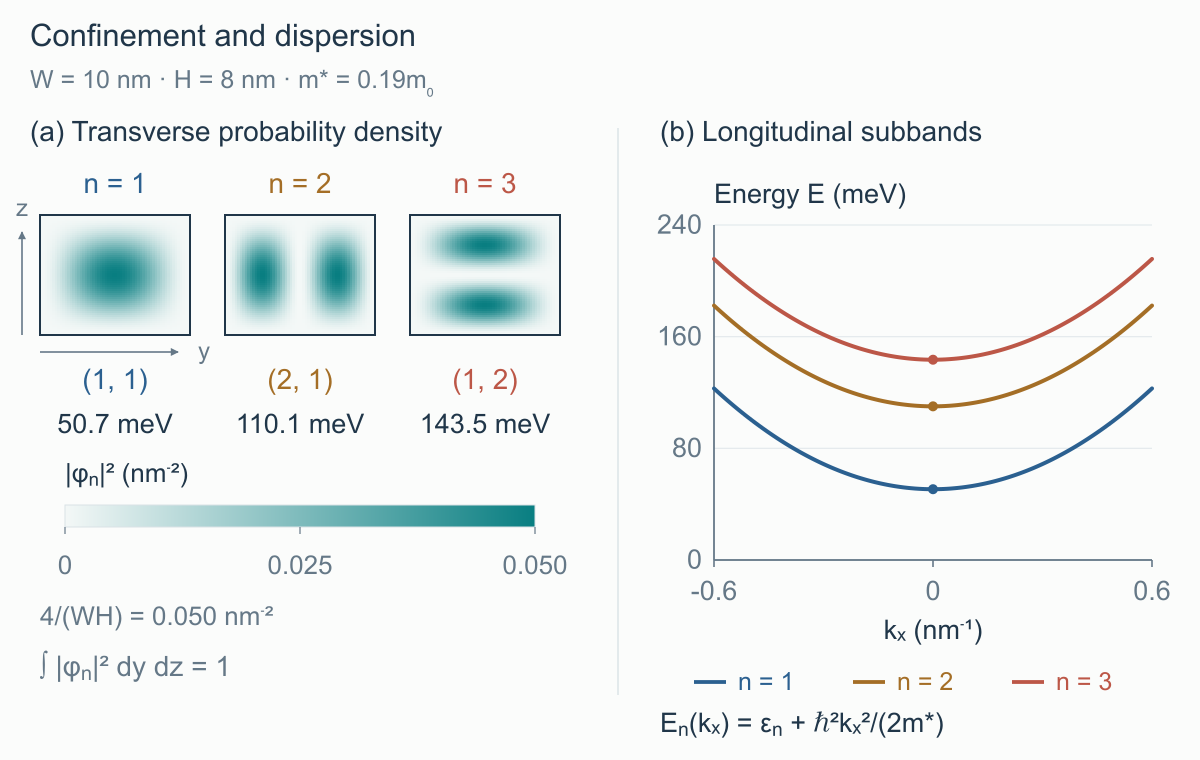

*Figure 2. Each transverse eigenstate has an eigenenergy that becomes a subband edge. Longitudinal kinetic energy raises the total energy above that edge. The transverse mode index and the sign of longitudinal momentum describe different things.*



[Open interactive example](https://pilkwangkim.github.io/posts/Multi-Subband-Boltzmann-Transport-From-Scratch/#lab-msbte-confinement)


Try narrowing the wire. Check whether all edges shift by the same amount, and identify which mode is most sensitive to the dimension you changed.

## 5. From quantum modes to MS-BTE: three different operations

Constructing a confined-system BTE starts by choosing states from the quantum Hamiltonian, then deciding which information about those states the transport model retains. It is not an exact rewriting of a bulk classical distribution with different variable names.

### A complete basis change retains the quantum state

An orthonormal basis lets us describe a vector by coefficients rather than Cartesian components. The same idea works for the transverse wavefunction. At each $x$, let $\phi_n(x;y,z)$ form a **complete** orthonormal basis of the transverse problem. A wavefunction can be expanded as

$$
\Psi(x,y,z,t)=\sum_{n=1}^{\infty}\chi_n(x,t)\phi_n(x;y,z).
\tag{11}
$$

The functions $\chi_n$ retain the longitudinal quantum amplitudes, including their phases. With all modes and all resulting coupling terms kept, this is an exact representation of the chosen Hamiltonian, not yet a Boltzmann equation. In a uniform separable wire the transverse basis is independent of $x$, and the Hamiltonian separates as in Eq. (10). If the basis varies with $x$, differentiating Eq. (11) also differentiates $\phi_n$; the resulting mode-coupling terms must not silently disappear.

Symmetry can simplify the transverse eigenproblem, but an asymmetric or irregular cross-section still has transverse eigenstates. What makes a small-mode description promising is strong confinement and a limited energy range, not symmetry alone. A partial semiclassical limit can leave transverse motion quantum mechanical while making longitudinal motion kinetic; a rigorous collisionless derivation of this type is given by [Ben Abdallah and Méhats](https://doi.org/10.1016/j.matpur.2004.10.004). It does not, by itself, derive every scattering approximation used in a device model.

### Keeping populations but dropping coherence is a physical approximation

For a three-state, **one-electron** example, write the normalized amplitude vector $c$. Its **density matrix** is $\rho=cc^\dagger$: the diagonal entries are occupation probabilities in the chosen basis, and off-diagonal entries retain relative-phase information between different states. The dagger denotes complex-conjugate transpose. A basis change described by a unitary matrix $U$, with $U^\dagger U=I$, gives

$$
M=U^\dagger\rho U,\qquad
\operatorname{Tr}M=\operatorname{Tr}\rho=1,\qquad
\operatorname{Tr}M^2=\operatorname{Tr}\rho^2=1.
\tag{12}
$$

The **trace** is the sum of diagonal entries. Here it checks total probability. The number $\operatorname{Tr}\rho^2$ is called **purity**: it is one for a normalized state specified by a single amplitude vector. Its equality before and after this unitary transformation is an invariant check on a change that preserves the full state.

By contrast, replacing $M$ by its diagonal part $D$ discards off-diagonal information. It keeps the current populations in that basis but generally changes the state and can change future dynamics. Calling this “a change of basis” would hide a physical approximation.

A population kinetic model needs a reason why those coherences do not affect the observables being calculated. Weak coherent coupling can limit the generation of new coherence, but does not erase coherence already present in the initial state or injected by a contact. The preparation and contact model must also be compatible with a population description; dephasing or a justified averaging procedure may be needed. Transition-rate models usually make another assumption about scattering memory: a **Markov approximation** makes the change depend on the present distribution rather than its full history. Neither condition follows from confinement alone. [Milovanović, Sec. 4.2.1](https://www.iue.tuwien.ac.at/phd/milovanovic/diss_htmlse9.html); [Fischetti et al., Sec. II](https://in4.iue.tuwien.ac.at/pdfs/sispad2005/1562014.pdf)

### Keeping only a finite number of modes is a separate truncation

Suppose the first two states are retained and the third is omitted. For this toy model, the projection matrix is $P=\operatorname{diag}(1,1,0)$. Acting on the population approximation gives $R=PDP$. Its trace is the retained probability, not automatically one. **Renormalizing it would conceal the discarded weight.** A transport calculation instead checks convergence of density, current, and relevant transitions as the retained mode set is enlarged.


In [4]:
# A three-state algebra example; the rotation is not a physical subband model.
c = np.sqrt(np.array([0.6, 0.3, 0.1]))
rho = np.outer(c, c.conj())
theta = np.pi / 6
U = np.array([[np.cos(theta), -np.sin(theta), 0.0],
              [np.sin(theta),  np.cos(theta), 0.0],
              [0.0,            0.0,           1.0]])
M = U.conj().T @ rho @ U                # Same state in a different basis.
D = np.diag(np.diag(M))                # Discard coherence in that new basis.
P = np.diag([1.0, 1.0, 0.0])
R = P @ D @ P                          # Omit state 3 without renormalizing.
assert np.allclose(U.conj().T @ U, np.eye(3))
assert np.isclose(np.trace(M @ M), 1.0)
assert np.isclose(np.trace(D), 1.0) and np.trace(D @ D) < 1.0
assert np.isclose(np.trace(R), 0.9)
for name, matrix in (("rho", rho), ("M", M), ("D", D), ("R", R)):
    print(name, "trace =", round(float(np.trace(matrix)), 6),
          "Tr(matrix^2) =", round(float(np.trace(matrix @ matrix)), 6))


rho trace = 1.0 Tr(matrix^2) = 1.0
M trace = 1.0 Tr(matrix^2) = 1.0
D trace = 1.0 Tr(matrix^2) = 0.806477
R trace = 0.9 Tr(matrix^2) = 0.796477


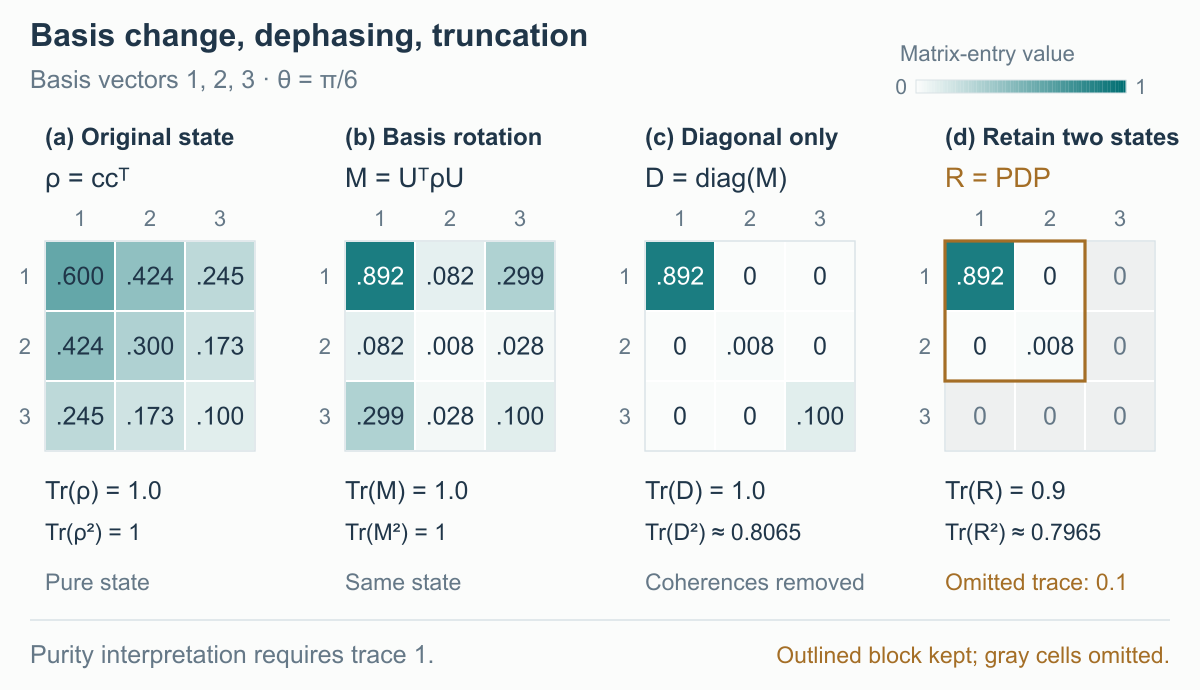

*Figure 3. The rotation preserves the state; deleting off-diagonal entries and discarding a state do not. Matrix entries are rounded to three decimals; invariants use unrounded values. The rotation mixes only the first two states, so the third state's weight remains 0.1. This one-electron algebra example is not a normalization rule for a device distribution, nor does 10% discarded probability imply 10% current error.*


### The resulting transport equation still belongs to the BTE framework

For a mode-resolved kinetic model, let $f_n(x,k,t)$ denote the local occupation per spin in subband $n$. A **population closure** supplies assumptions that let these occupations evolve without separately evolving the omitted amplitudes or correlations. The model also requires a **longitudinal semiclassical approximation**: quantum amplitudes along $x$ are replaced by a local phase-space description. Simply dropping transverse off-diagonal matrix entries does not accomplish this step. With subband energy $E_n(x,k)$, the scalar MS-BTE has the form

$$
\partial_t f_n
+\frac{\partial_k E_n}{\hbar}\partial_x f_n
-\frac{\partial_x E_n}{\hbar}\partial_k f_n
=C_n[\lbrace f_m\rbrace].
\tag{13}
$$

The left side propagates occupations in each subband. The right side couples subbands through scattering, so reduced dimensionality does not mean independent transport channels. In the parabolic model, $\partial_xE_n=\partial_x\epsilon_n$. [Noei et al., Eq. (3)](https://link.springer.com/article/10.1007/s10825-020-01488-4)

The practical reduction has several ingredients: quantum transverse states supply a mode label; longitudinal semiclassical kinetics and a population/rate description remove information not tracked by scalar $f_n$; a finite $N_s$ restricts the retained state space. Only the first is a basis choice. The last needs numerical convergence tests, and the middle needs physical validity checks. A complete coherent mode expansion could instead be used inside a quantum-transport calculation.



**Where did the longitudinal quantum amplitudes go?**


In an $x$-independent transverse basis, a quantum one-particle density matrix has elements $\rho_{nm}(x,x',t)$. For a device, its trace counts electrons per spin; it need not be one like the single-electron toy above. Two position arguments retain coherence between different locations, in addition to coherence between modes $n,m$. One can re-express the relative coordinate $\xi=x-x'$ by a Fourier transform:

$$
\begin{aligned}
F_{nm}(x,k,t)&=\int d\xi\,e^{-ik\xi}
\rho_{nm}\!\left(x+\frac{\xi}{2},x-\frac{\xi}{2},t\right),\\
\int\frac{dk}{2\pi}F_{nm}(x,k,t)&=\rho_{nm}(x,x,t).
\end{aligned}
\tag{14}
$$

This **partial Wigner transform** changes how the same information is represented. It is not yet a positive classical distribution: even $F_{nn}$ may be negative, and its exact evolution can contain nonlocal quantum terms. Deleting $n\ne m$ elements alone does not remove those longitudinal features. **Coarse-graining** averages over fine spatial or momentum structure instead of resolving every quantum oscillation. A semiclassical gradient/coarse-graining approximation, an appropriate population closure, and a collision model are needed before interpreting local $f_n$ as the occupations used in Eq. (13). An $x$-dependent transverse basis introduces additional derivative couplings as well. Thus no single “replace the wavefunction by probabilities” operation derives MS-BTE.





**Why this is not Brillouin-zone folding**


Transverse confinement quantizes allowed motion through a boundary-value problem. **Brillouin-zone folding** instead relabels crystal wavevectors when a larger periodic unit cell makes the reciprocal-space cell smaller. Both can produce several curves in a band plot, but they are different constructions. A hard-wall wire has subbands without invoking zone folding. Material-specific band-structure calculations may use folding techniques separately. [ABINIT: fold2bloch](https://docs.abinit.org/tutorial/fold2bloch/)



## 6. Velocity and force come from the same energy


A plane wave is spatially extended, so a transport trajectory is not the path of that exact stationary state. A **wavepacket** combines nearby $k$ values and can have an approximately localized centre. A semiclassical description follows that centre while using the subband dispersion for its energy. It requires a packet narrow enough in momentum to have a useful central $k$, yet small enough in position that the potential varies little across it. This is a scale assumption, not an exact point-particle interpretation of a plane wave. [Xiao, Chang, and Niu, Secs. IV–V](https://doi.org/10.1103/RevModPhys.82.1959)

In a nonuniform wire, a changing cross-section or potential can make the edge $\epsilon_n(x)$ depend on position. The uniform example is the special case with constant edges. For the scalar parabolic model, the equations for the packet centre are

$$
\begin{aligned}
E_n(x,k)&=\epsilon_n(x)+\frac{\hbar^2 k^2}{2m^*},\\
\dot x=v_n(k)&=\frac{1}{\hbar}\partial_k E_n
=\frac{\hbar k}{m^*},\\
\hbar\dot k=F_n(x)&=-\partial_x\epsilon_n(x).
\end{aligned}
\tag{15}
$$

$k$ is a wavevector, while the longitudinal crystal momentum in this approximation is $\hbar k$. The group velocity is the slope of the dispersion divided by $\hbar$. A rising subband edge exerts a force toward smaller $x$.

If the electrostatic potential is $\varphi(x)$, an electron has potential energy $-e\varphi$. When $\epsilon_n$ already contains this term, $-\partial_x\epsilon_n$ already contains the electric force. Adding a separate $-e\mathcal E$ term would count that force twice. With $\mathcal E=-\partial_x\varphi$, the signs agree: $-\partial_x(-e\varphi)=-e\mathcal E$.

This also explains why a narrowing wire can oppose motion even without a separately applied longitudinal electric field: stronger confinement raises $\epsilon_n(x)$. For a time-independent energy landscape, Eq. (15) conserves $E_n$ between collisions, because

$$
\frac{dE_n}{dt}
=\partial_xE_n\,\dot x+\partial_kE_n\,\dot k=0.
\tag{16}
$$



**Visual example: an electron slows while the subband edge rises**



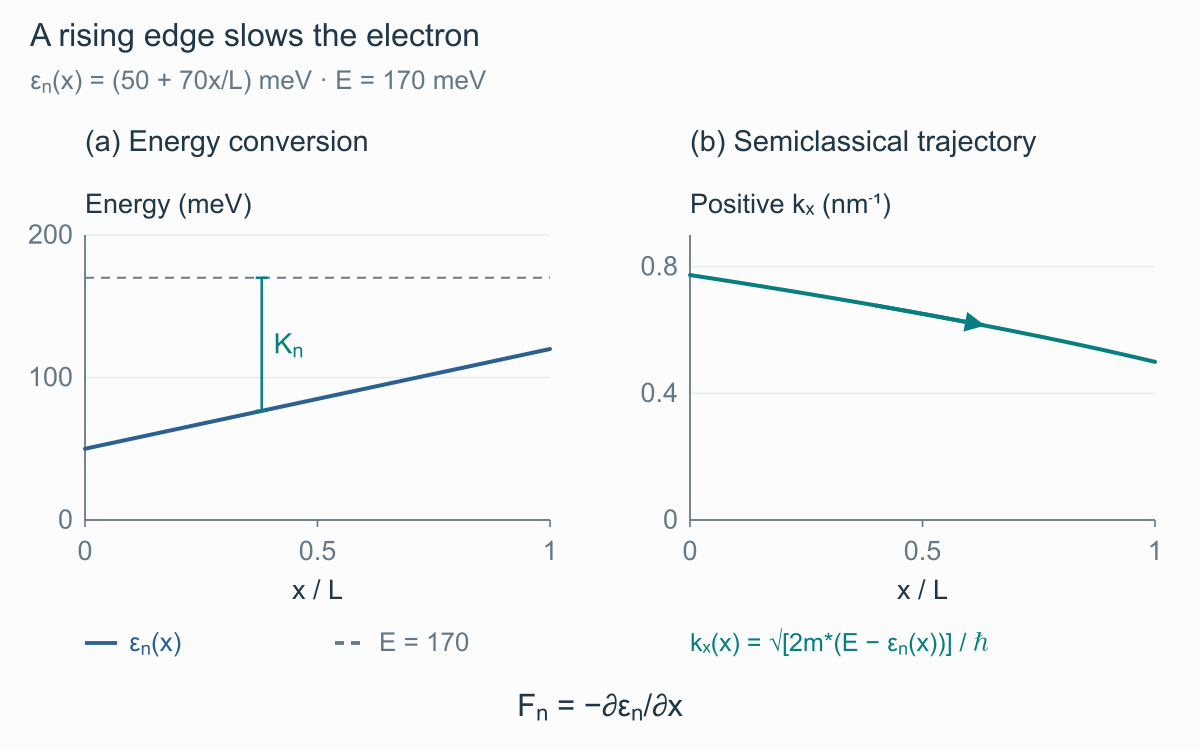

*The prescribed edge rises from 50 to 120 meV while total energy stays at 170 meV. Longitudinal kinetic energy falls from 120 to 50 meV, so a right mover slows down without reaching a turning point. The momentum plot shows the semiclassical centre's path in position–momentum space, not an oscillating wavefunction.*






**When may a transverse mode be followed along a nonuniform wire?**


At each $x$, solve a transverse eigenproblem $\widehat H_\perp(x)\phi_n(x;y,z)=\epsilon_n(x)\phi_n(x;y,z)$. Expanding the full wavefunction in this local basis introduces terms containing $\partial_x\phi_n$ and $\partial_x^2\phi_n$. They can couple different modes coherently.

Keeping only separate subband populations assumes those omitted coherent couplings are negligible for the situation of interest. Smooth variation and sufficiently separated modes help, but a slowly drawn geometry alone is not a universal error bound: small mode gaps and near crossings need special care. An abrupt constriction can cause quantum reflection and coherent mode conversion that the simple population model does not calculate.

In the uniform example, the transverse basis is independent of $x$, so these derivative couplings vanish. Longitudinal phase interference is still not tracked by an occupation-only BTE.




## 7. Density and current from occupations


The subband energies now specify the available states, and $f_n(x,k,t)$ supplies their occupations. To obtain density or current, each occupation must be multiplied by the number of states it represents. For example, many distinct states can each have mean occupation 0.8; their contributions add rather than being normalized to a total of one.

The bound $0\le f_n\le1$ is **Pauli exclusion** for a state of fixed spin. It does not make $f_n$ a position probability density like $\lvert\Psi\rvert^2$. Its local coordinates label coarse-grained packet centres, still subject to $\Delta x\,\Delta k\ge1/2$. That uncertainty bound does not itself justify neglecting coherence; the difference remains visible in the example below.



**The same populations can hide different interference patterns**


For one electron of fixed spin in one transverse mode, consider the longitudinal states $\psi_\pm(x)=e^{\pm ikx}/\sqrt{\mathcal L}$ with nonzero allowed $k$. Compare two preparations:

- A coherent superposition $\psi=(\psi_++\psi_-)/\sqrt2$ retains a fixed relative phase.
- A statistical mixture chooses $\psi_+$ or $\psi_-$ with probability $1/2$, rather than adding their amplitudes in each preparation.

Both assign population $1/2$ to each momentum state and have zero net current, but their longitudinal position probabilities differ:

$$
\begin{aligned}
p_{\rm coherent}(x)&=\frac{1+\cos(2kx)}{\mathcal L},\\
p_{\rm mixture}(x)&=\frac{1}{\mathcal L}.
\end{aligned}
$$

The cosine is a cross term between amplitudes. A population-only description does not retain the relative phase needed to reconstruct it. Thus separation into transverse modes does not, by itself, justify discarding interference. MS-BTE is appropriate when the retained population observables and the physical coherence scales support that approximation. Even a collisionless BTE remains a population model; absence of scattering does not restore the discarded phase information.



To count states, temporarily impose periodic boundaries on a long normalization length $\mathcal L$. The condition $e^{ik\mathcal L}=1$ gives $k_j=2\pi j/\mathcal L$, hence spacing $\Delta k=2\pi/\mathcal L$. A $k$ interval $dk$ therefore contains approximately $\mathcal L\,dk/(2\pi)$ states per spin in the large-box limit.

This periodic box is only a **state-counting device**, not the physical contact boundary condition. Dividing by length removes $\mathcal L$; the actual open wire will receive the incoming distributions specified in Eq. (21). Including spin degeneracy $g_s=2$ gives

$$
\begin{aligned}
N_n(x,t)&=\frac{g_s}{2\pi}\int_{-\infty}^{\infty} f_n(x,k,t)\,dk,\\
N(x,t)&=\sum_n N_n(x,t),\\
\Phi(x,t)&=\frac{g_s}{2\pi}\sum_n\int_{-\infty}^{\infty}v_n(k)f_n(x,k,t)\,dk.
\end{aligned}
\tag{17}
$$

$N_n$ and $N$ are **line densities**, measured in electrons per metre. $\Phi$ is the signed electron number flux, measured in electrons per second. Positive $\Phi$ means electrons move on balance from left to right. The signed conventional charge current in that same coordinate direction is

$$
I_{\rm charge}=-e\Phi,
\qquad I_e=e\Phi=-I_{\rm charge}.
\tag{18}
$$

The current examples use $I_e$ for electron flow; the injection lab also reports $I_{\rm charge}=-I_e$. Positive $I_e$ means net left-to-right electron flow, not positive conventional charge flow.

For a counting example, suppose a $k$ interval contains 20 states per spin in a $1\,\mu\mathrm m$ normalization length, each with occupation 0.25. Its mean electron number is $2\times20\times0.25=10$, not 0.25; its line density is $10\,\mu\mathrm m^{-1}$. Multiplying a right-moving line-density contribution by its speed gives the number crossing a section each second: during $dt$, the electrons in a length $v\,dt$ pass that section. This is the velocity factor in Eq. (17).

If $f_n(k)=f_n(-k)$, density can be large while current is zero: the velocities cancel. Current measures a **directional imbalance**, not just how many electrons are present.



**How does line density become a three-dimensional charge density?**


The transverse mode determines where each subband's electrons are distributed across the wire:

$$
n_{3D}(x,y,z,t)=\sum_n N_n(x,t)\lvert\phi_n(x;y,z)\rvert^2.
\tag{19}
$$

$\lvert\phi_n\rvert^2$ has units $\mathrm{m}^{-2}$, so $N_n\lvert\phi_n\rvert^2$ has units $\mathrm{m}^{-3}$. Integrating Eq. (19) over the cross-section returns $N$. This expression neglects off-diagonal coherence between different transverse modes, consistently with the population model.



## 8. Contacts set the incoming half of the distribution


A **reservoir** is a large contact assumed to maintain thermal equilibrium even while exchanging electrons with the small wire. Electrons leaving the wire are absorbed and re-equilibrated there; the contact is not an extra hard wall. Its temperature $T$ describes thermal broadening. Its **chemical potential** $\mu$ sets the energy around which states change from mostly occupied to mostly empty. In transport notation this reservoir energy is also called its **electrochemical potential** or Fermi level: it uses the same total-energy reference as $E$, including the electrostatic contribution. It is not the energy of every electron.

For independent fermionic states, the equilibrium occupation is the **Fermi–Dirac distribution**:

$$
f_{\rm FD}(E;\mu,T)=\frac{1}{1+\exp[(E-\mu)/(k_BT)]}.
\tag{20}
$$

$k_B$ is Boltzmann's constant: it converts temperature into the energy scale $k_BT$. At positive $T$, the occupation equals $1/2$ at $E=\mu$. Far below $\mu$ it approaches 1; far above it approaches 0. As $T\to0$, it becomes a step. At $300\,\mathrm K$, $k_BT\simeq25.85\,\mathrm{meV}$. The Fermi–Dirac statistics and chemical potential are discussed in [MIT's statistical-mechanics notes](https://www.mit.edu/~jgt/Content-Web/Teaching/8333/8333%202025%20Lecture%2028.pdf).

Thermal equilibrium is physical input in addition to the single-particle Hamiltonian. For one state per spin, the equilibrium statistical weights of the empty and occupied possibilities are $w_0=1$ and $w_1=\exp[-(E-\mu)/(k_BT)]$. Normalizing these two weights gives $f=w_1/(w_0+w_1)$, which is Eq. (20). For example, $E-\mu=k_BT\ln3$ gives $w_1=1/3$ and occupation $1/4$; changing the sign gives $w_1=3$ and occupation $3/4$.

Only the difference $E-\mu$ matters. Shifting all energies, including both contact chemical potentials, by the same constant changes no occupation. Keeping two reservoirs in equilibrium separately does not put the wire in one common equilibrium: different contact values can maintain a directional imbalance inside it.

At $x=0$, right-moving electrons enter from the left reservoir. At $x=L$, left-moving electrons enter from the right reservoir. Hence

$$
\begin{aligned}
f_n(0,k>0)&=f_{\rm FD}(E_n(0,k);\mu_L,T_L),\\
f_n(L,k<0)&=f_{\rm FD}(E_n(L,k);\mu_R,T_R).
\end{aligned}
\tag{21}
$$

The outgoing halves are **unknowns determined by transport**, not additional equilibrium boundary values. Fixing both directions at both ends generally overconstrains a transport problem and overwrites information about backscattering. Incoming thermal-bath boundary conditions are used explicitly by [Noei et al.](https://link.springer.com/article/10.1007/s10825-020-01488-4).

For a uniform, collisionless wire with no reflecting barrier, each incoming occupation stays constant along its trajectory:

$$
f_n(x,k)=
\begin{cases}
f_L(E_n(k)),&k>0,\\
f_R(E_n(k)),&k<0.
\end{cases}
\tag{22}
$$

Here $f_L$ and $f_R$ abbreviate the two reservoir distributions. A finite current needs no internal longitudinal field in this fixed, flat-channel model: unequal reservoir occupations supply unequal incoming fluxes. The voltage drop and electrostatics of a real device require more information than this prescribed channel.


In [5]:
def fermi(E_eV, mu_eV, temperature_K):
    if temperature_K <= 0:
        raise ValueError("Use positive temperature in this example")
    z = (np.asarray(E_eV) - mu_eV) / (KB_EV * temperature_K)
    # logaddexp prevents overflow in the exponential far above mu.
    return np.exp(-np.logaddexp(0.0, z))

energy = 0.130  # eV, the same TOTAL energy for every open subband
print(fermi(energy, 0.150, 300), fermi(energy, 0.100, 300))
assert np.isclose(fermi(0.150, 0.150, 300), 0.5)


0.6843065931015321 0.2385851982237299


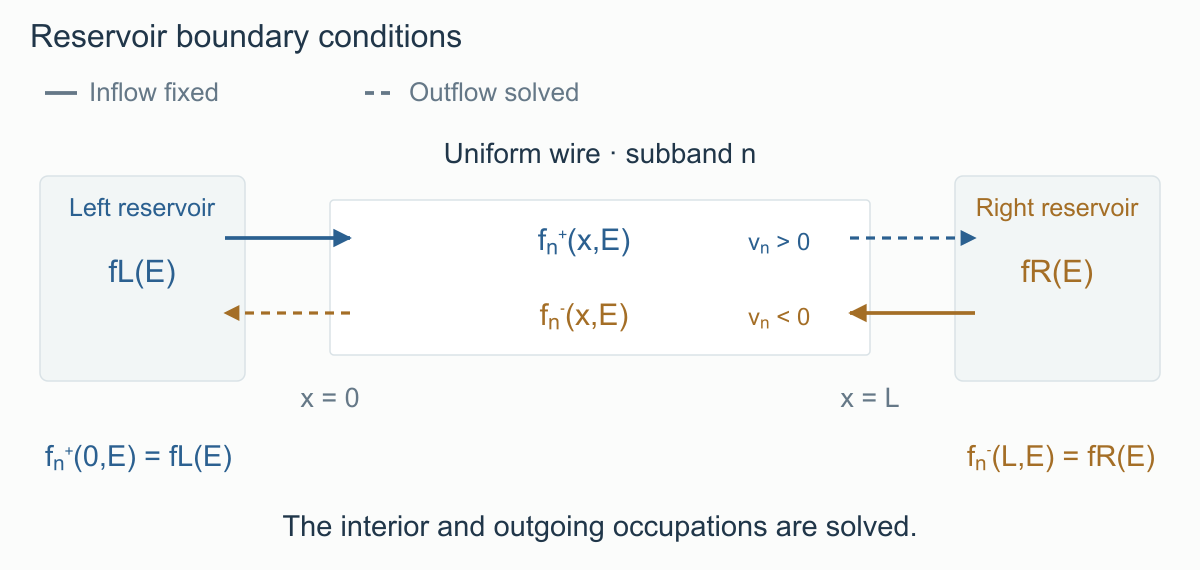

*Figure 4. Solid arrows mark prescribed inflow; dashed arrows mark outgoing occupations to be solved. Scattering inside the wire changes what leaves each contact, so the outgoing occupations cannot also be fixed independently.*



[Open interactive example](https://pilkwangkim.github.io/posts/Multi-Subband-Boltzmann-Transport-From-Scratch/#lab-msbte-injection)


Set the two chemical potentials equal. The density does not vanish, but the two directional currents cancel. Then separate them while keeping the subband edges fixed. The current readout uses the analytic energy integral derived in Eq. (41).

<span id="5-the-boltzmann-equation-follows-occupation-along-a-trajectory"></span>



**Check: equilibrium in a nonuniform, static potential**


With one common $\mu,T$, take $f_n^{\rm eq}(x,k)=f_{\rm FD}(E_n(x,k);\mu,T)$. Let $f'_{\rm FD}$ denote the energy derivative. The two streaming terms cancel:

$$
v_n f'_{\rm FD}\partial_x\epsilon_n
-\frac{\partial_x\epsilon_n}{\hbar}
f'_{\rm FD}\partial_kE_n=0.
\tag{23}
$$

Thus a spatially changing equilibrium occupation is not by itself a current source. Acceleration and spatial streaming must be discretized together if a numerical solver is to preserve this equilibrium. The uniform solver below avoids this additional numerical problem by setting $\partial_x\epsilon_n=0$. Full equilibrium also requires $C[f^{\rm eq}]=0$; detailed balance below supplies that collision check.



## 9. Scattering is gain minus loss, not disappearance


A collision changes an electron's state. It need not remove the electron from the wire. An **intra-subband** collision keeps $n$ unchanged; an **inter-subband** collision changes it. Either may change the direction of motion.

To write an unambiguous counting equation, first use discrete, box-normalized states $a=(n,k_j)$ for one spin. The position and time labels are suppressed in this local collision calculation. Let $W_{a\to b}$ be the **unblocked transition-rate coefficient** to a particular final state $b$. Over a sufficiently short $dt$, the transition probability before checking final-state occupation is approximately $W_{a\to b}dt$. A rate has units $\mathrm{s}^{-1}$ and need not be less than one. Then

$$
C_a[f]=\sum_b\left[
W_{b\to a}f_b(1-f_a)
-W_{a\to b}f_a(1-f_b)
\right].
\tag{24}
$$

The gain term requires an occupied source $b$ and an empty destination $a$. The loss term requires the reverse. The factors $1-f$ express **Pauli blocking**: an already occupied single-particle state cannot accept another electron of the same spin. This is an independent-occupation model of one-electron transitions caused by prescribed scatterers or a bath, not the most general BTE collision integral. Electron–electron scattering needs a two-particle transition kernel and additional occupation factors. In the continuum limit the sum becomes an integral with the appropriate state-counting measure.

For example, take $f_a=0.8$, $f_b=0.2$, and reciprocal rates $W_{a\to b}=W_{b\to a}=1000\,\mathrm{s}^{-1}$. The gain into $a$ is $1000(0.2)(0.2)=40\,\mathrm{s}^{-1}$ and its loss is $1000(0.8)(0.8)=640\,\mathrm{s}^{-1}$. Thus $C_a=-600\,\mathrm{s}^{-1}$ while $C_b=+600\,\mathrm{s}^{-1}$. Electrons move between states; a negative occupation derivative is not disappearance of charge.

Where do the rates come from? For a weak, static perturbation $V$ and a continuum of available final states, **Fermi's golden rule** gives the elastic transition-rate kernel

$$
W_{a\to b}=\frac{2\pi}{\hbar}
\lvert\langle b\vert V\vert a\rangle\rvert^2\delta(E_b-E_a).
\tag{25}
$$

The delta function enforces energy conservation when integrated over final states; it is not a finite number to evaluate at zero. The matrix element contains the spatial overlap of the initial state, perturbation, and final state. Consequently, subband energies alone do not determine inter-subband rates: the transverse wavefunctions matter too. Time-dependent perturbation theory and its long-time transition-rate limit are derived in [MIT's quantum-theory notes](https://ocw.mit.edu/courses/8-321-quantum-theory-i-fall-2017/81f6e90a6cdd311ca5f3afb32e9da1f2_MIT8_321F17_lec26.pdf).



**Two accessible subbands do not automatically scatter into each other**


In the uniform wire, the transverse part of a perturbation matrix element is

$$
V_{mn}(x)=\int dy\,dz\,
\phi_m^*(y,z)V(x,y,z)\phi_n(y,z).
$$

If the perturbation is constant across the cross-section, $V(x,y,z)=V(x)$, orthonormality gives $V_{mn}(x)=V(x)\delta_{mn}$. Here $\delta_{mn}$ equals 1 for the same mode and 0 for different modes. Such a perturbation cannot mix different transverse modes in this separable model. A perturbation with transverse structure can have nonzero off-diagonal matrix elements. Energy conservation identifies possible final energies; overlap and the perturbation determine whether the transition actually has a nonzero rate.



For scattering by a lattice vibration, a **phonon** carries energy $\hbar\omega$. Absorption gives $E_b=E_a+\hbar\omega$; emission gives $E_b=E_a-\hbar\omega$. The corresponding rates also contain phonon occupation factors. The lattice can act as a **thermal bath**, a large environment maintained at a temperature while exchanging energy with the electrons. The electron's energy need not be conserved, although the combined electron-plus-bath energy is. Contact reservoirs set incoming electron occupations; a phonon bath sets absorption and emission rates. They play different roles. A full material model distinguishes these mechanisms rather than assigning every event the same rate.

### Why equilibrium is a stronger check than zero current

The Fermi function satisfies $f_a/(1-f_a)=\exp[-(E_a-\mu)/(k_BT)]$. For an allowed pair with nonzero forward and reverse rates, pairwise cancellation in Eq. (24) therefore follows when

$$
\frac{W_{a\to b}}{W_{b\to a}}
=\exp\!\left[-\frac{E_b-E_a}{k_BT}\right].
\tag{26}
$$

This pairwise equilibrium relation is **detailed balance**. Here the transition rates describe coupling to a thermal bath at temperature $T$; the forward and reverse equilibrium traffic balance separately. A distribution can have zero current but still relax in energy, so checking $I=0$ alone does not establish $C[f]=0$.

It is the **occupation-weighted traffic**, not necessarily the bare rates, that is equal. For instance, let $E_a=\mu$ and $E_b=\mu+k_BT$. Then $f_a=1/2$, $f_b=1/[1+\exp(1)]$, and $W_{a\to b}=\exp(-1)W_{b\to a}$. Both blocked equilibrium traffic terms equal $W_{b\to a}/[2(1+\exp(1))]$. If both rates vanish because a transition is forbidden, both traffic terms are already zero and no rate ratio needs to be formed.

For elastic reciprocal scattering, $E_a=E_b$ and the microscopic forward/reverse rates agree. Then

$$
f_b(1-f_a)-f_a(1-f_b)=f_b-f_a.
\tag{27}
$$

The elastic operator can thus be linear in $f$ without assuming $f\ll1$. This cancellation does **not** justify dropping Pauli blocking in a general inelastic calculation.

## 10. Particle conservation gives a non-negotiable test


Sum Eq. (24) over every state $a$. Every transition's loss from its source is its gain at its destination. Relabeling $a,b$ gives $\sum_a C_a=0$. In continuum notation,

$$
\sum_n\frac{g_s}{2\pi}\int C_n[f]\,dk=0.
\tag{28}
$$

Individual subbands need not conserve their own populations. Their exchange terms must cancel only after summing all coupled subbands.

Integrating Eq. (13) over $k$ and summing $n$ now gives

$$
\partial_tN+\partial_x\Phi=0.
\tag{29}
$$

Here the mass is constant, and the distribution vanishes at large $\lvert k\rvert$, so the force term integrates to zero. Eq. (29) is the **continuity equation**: a segment accumulates electrons only if more enter than leave. At stationarity, $\partial_x\Phi=0$. A computed current that steadily disappears along a source-free wire is a numerical or model-consistency failure, not ordinary scattering.

The cancellations can be checked separately: $\int\partial_kf_n\,dk=f_n(+\infty)-f_n(-\infty)=0$, and the sum of collision contributions is Eq. (28). Since $v_n(k)$ is independent of $x$ for the constant-mass dispersion, the remaining spatial integral is $\partial_x\Phi$. Stationarity constrains the **net** flux: the two directional flux magnitudes can vary with position while their difference stays fixed. Backscattering redistributes carriers between directions.



**Why a naive relaxation-time term can fail this test**


A common **relaxation-time approximation**, or **RTA**, is $C_n=-(f_n-f_n^{\rm target})/\tau$. It drives the distribution toward a chosen target on a timescale $\tau$.

If that target has the wrong local density, integrating $C$ produces $(N^{\rm target}-N)/\tau$: the model creates or destroys particles. A density-matched target can avoid this particular error; other conservation laws and the scattering mechanism still need examination. A fixed equilibrium target is appropriate for some open-system relaxation models, but not automatically for particle-conserving collisions inside a closed channel segment.

Purely elastic scattering redistributes direction and subband at fixed total energy. It cannot generally thermalize an arbitrary energy distribution to one Fermi function. The distinction between an even-in-momentum distribution and a local thermal distribution is important in analytical elastic BTE solutions. [Baccarani et al.](https://in4.iue.tuwien.ac.at/pdfs/sispad2008/pdfs/4648223.pdf)



## 11. Elastic inter-subband scattering changes longitudinal kinetic energy


For a fixed total energy $E$, an open subband has

$$
\begin{aligned}
K_n(E)&=E-\epsilon_n>0,\\
k_{n,\pm}(E)&=\pm\frac{\sqrt{2m^*(E-\epsilon_n)}}{\hbar},\\
v_n(E)&=\sqrt{\frac{2(E-\epsilon_n)}{m^*}}>0.
\end{aligned}
\tag{30}
$$

$v_n(E)$ here denotes the **speed**; the signed velocity of direction $s=\pm1$ is $s v_n(E)$. If $E<\epsilon_n$, that subband has no propagating longitudinal state at that energy.

Take $E=130\,\mathrm{meV}$ in the $10\times8\,\mathrm{nm}^2$ wire. The first two subbands are open. An elastic transition from mode 1 to mode 2 reduces the longitudinal kinetic energy from about $79.3$ to $19.9\,\mathrm{meV}$. The total remains $130\,\mathrm{meV}$ because the transverse energy increased by the same amount. The third mode is closed at this energy. Keeping the same $k$ while changing the mode would violate energy conservation for unequal edges and equal masses.


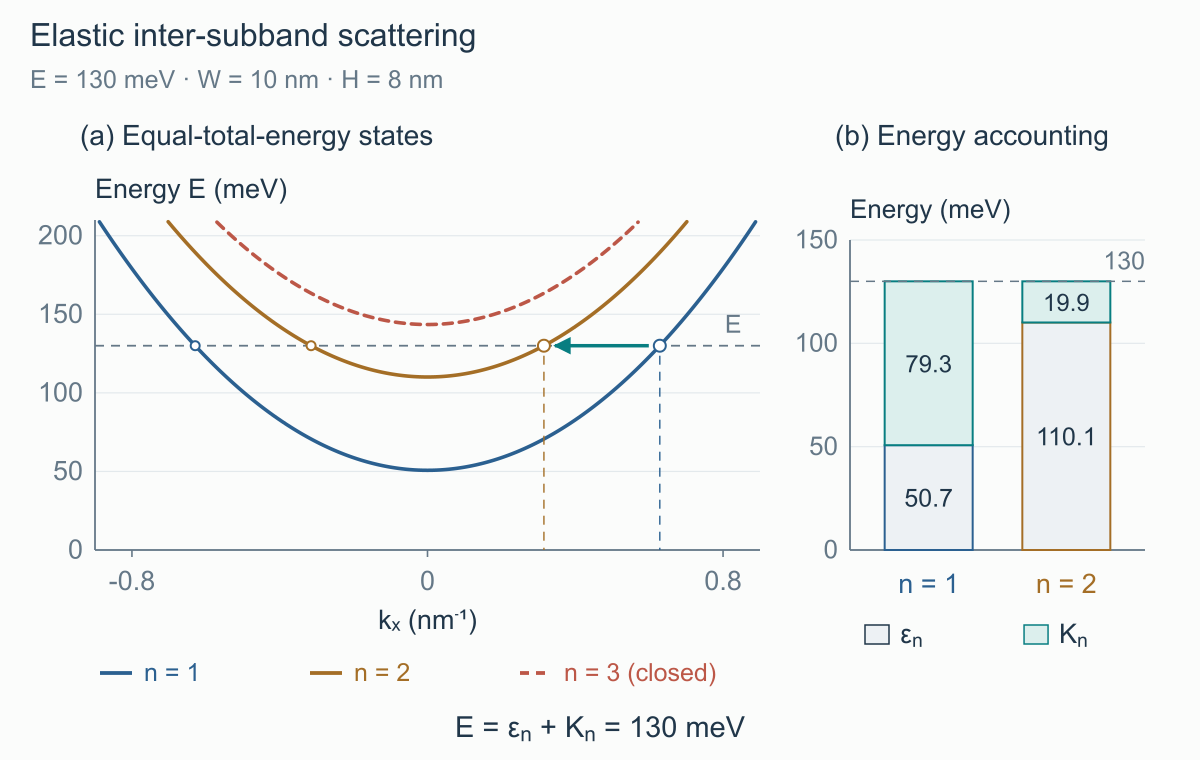

*Figure 5. Elastic transitions connect equal total energies, not equal longitudinal kinetic energies. Of the two open modes, mode 2 leaves less energy for longitudinal motion and has the smaller momentum magnitude. The teal arrow connects two positive momenta: this event slows a right mover without reversing its direction. It is a transition in momentum space, not a real-space trajectory. The energy stacks separate each subband edge from its longitudinal kinetic energy; both sum to 130 meV. The dashed third subband is closed at this energy.*


### The one-dimensional density of states

At fixed $x$, write $f_{n,s}(x,E)=f_n(x,k_{n,s}(E))$. This changes the label used for the same occupation; it does not introduce a new distribution normalized over energy. For either direction, $\lvert dE/dk\rvert=\hbar v_n$, hence $\lvert dk/dE\rvert=1/(\hbar v_n)$. The occupied state count in a narrow energy interval is therefore

$$
dN_{n,s}=\frac{g_s}{2\pi}f_{n,s}\left\lvert\frac{dk}{dE}\right\rvert dE
=\frac{g_s}{h v_n}f_{n,s}\,dE.
$$

This defines the **density of states**, the number of available states per energy interval, here also per unit wire length. It gives

$$
\begin{aligned}
w_{n,s}(E)&=\frac{g_s}{h v_n(E)},\\
N_n(x)&=\int_{\epsilon_n}^{\infty}
\frac{g_s}{h v_n(E)}[f_{n,+}(x,E)+f_{n,-}(x,E)]\,dE,\\
\Phi(x)&=\frac{g_s}{h}\sum_n\int_{\epsilon_n}^{\infty}
[f_{n,+}(x,E)-f_{n,-}(x,E)]\,dE.
\end{aligned}
\tag{31}
$$

$h=2\pi\hbar$. The weight $w_{n,s}$ is the number of states per length and per energy for one direction, including spin. Energies in these integrals are in joules when SI values of $h$ and velocity are used.

The density weight diverges as $1/\sqrt{E-\epsilon_n}$ near an edge. The divergence is integrable, but evaluating it exactly at the threshold is a bad **quadrature** rule—a numerical integration rule that replaces an integral by a weighted sum of sampled values. By contrast, speed cancels from the flux: $v_n w_{n,s}=g_s/h$. Slow states contribute more density per energy interval but less velocity per electron. Threshold singularities are a known difficulty of energy-space nanowire BTE discretizations. [Noei et al.](https://link.springer.com/article/10.1007/s10825-020-01488-4)

At $130\,\mathrm{meV}$ in the example wire, the two speeds are about $3.83\times10^5$ and $1.92\times10^5\,\mathrm{m/s}$. Treating the DOS as constant across a narrow $1\,\mathrm{meV}$ window near that energy gives approximately 1.26 and 2.52 available states per micrometre **per direction**, including spin. The slower mode has about twice the density weight. Multiplying each weight by its speed removes that difference in the flux formula.

## 12. A small coupled collision model that conserves particles


An elastic, uniform wire can be solved independently at each total energy. A **branch** here means one subband together with one direction of motion. At $130\,\mathrm{meV}$, the four open branches are ordered as $a=(1,+),(1,-),(2,+),(2,-)$. Let $f_a(x)$ be their occupations.

To avoid introducing unverified material parameters, define a **phenomenological** model: its coefficients are chosen to obey stated physical constraints rather than derived from a particular microscopic mechanism. Use symmetric nonnegative coefficients $\kappa_{ab}=\kappa_{ba}$, with units of inverse length and $\kappa_{aa}=0$. Set

$$
\begin{aligned}
C_a[f]&=v_a\sum_b\kappa_{ab}(f_b-f_a),\\
s_a\frac{df_a}{dx}&=\sum_b\kappa_{ab}(f_b-f_a).
\end{aligned}
\tag{32}
$$

The second line is the stationary BTE $s_av_a\partial_xf_a=C_a$ after division by speed. A coefficient $\kappa_{ab}$ is **not itself a rate in inverse seconds**: the loss-rate coefficient is $v_a\kappa_{ab}$. This particular velocity dependence defines the example. Real microscopic scattering generally has more complicated energy and subband dependence.

Why choose symmetry in $\kappa$ rather than equal branch-to-branch rates? Because equal energy intervals contain different numbers of states when speeds differ. Multiplying $C_a$ by its density weight gives

$$
\sum_a w_a C_a
=\frac{g_s}{h}\sum_{a,b}\kappa_{ab}(f_b-f_a)=0.
\tag{33}
$$

Every pair cancels. A common occupation $f_a=f_0(E)$ is also stationary under collisions. The model thus conserves electron number at each energy and leaves a common Fermi occupation unchanged. It redistributes populations but does not relax energy.

Use $\beta_n$ for the intra-subband $+\leftrightarrow-$ pair. For each pair of different subbands, connect all four direction combinations with $\gamma/2$. Each starting branch can reach two directions in the other subband, so their inverse-length coefficients sum to $\gamma$. This factor of two is a convention for splitting the coupling between final directions, not a phonon selection rule. For the four-branch order above,

$$
\kappa=\begin{pmatrix}
0&\beta_1&\gamma/2&\gamma/2\\
\beta_1&0&\gamma/2&\gamma/2\\
\gamma/2&\gamma/2&0&\beta_2\\
\gamma/2&\gamma/2&\beta_2&0
\end{pmatrix}.
$$

Both same-direction conversion and direction reversal are possible. The code calls this matrix `K`; it is not the longitudinal kinetic energy $K_n$ of Eq. (30).

The DOS weights matter even for one coupled pair from different subbands. In consistent length/time units, take $v_a=2$, $v_b=1$, $\kappa_{ab}=0.1$, $f_a=0.8$, and $f_b=0.2$. This pair contributes $C_a=-0.12$ and $C_b=+0.06$. The occupation changes do not sum to zero, but $C_a/v_a+C_b/v_b=-0.06+0.06=0$: twice as many states per energy are available in the slower branch. These are the two branches' contributions to number conservation, not equal-sized boxes of electrons.


In [6]:
def coupling_matrix(n_modes, beta=0.02, gamma=0.01):
    # Order: (mode 1,+), (mode 1,-), (mode 2,+), (mode 2,-), ...
    # beta and gamma are in nm^-1 because the solver uses x in nm.
    K = np.zeros((2 * n_modes, 2 * n_modes))
    for n in range(n_modes):
        K[2*n, 2*n+1] = K[2*n+1, 2*n] = beta
    for n in range(n_modes):
        for m in range(n + 1, n_modes):
            K[2*n:2*n+2, 2*m:2*m+2] = gamma / 2
            K[2*m:2*m+2, 2*n:2*n+2] = gamma / 2
    return K

def collision_rhs(f, speeds, K):
    # Occupations, not particle counts, are the inputs.
    # Multiplication by speed converts inverse length into inverse time.
    return speeds * (K @ f - K.sum(axis=1) * f)

speed_units = np.array([2., 2., 1., 1.])
K_demo = coupling_matrix(2)
C_demo = collision_rhs(np.array([.9, .1, .3, .3]), speed_units, K_demo)
assert abs(np.sum(C_demo / speed_units)) < 1e-14
assert np.allclose(collision_rhs(np.full(4, .4), speed_units, K_demo), 0)


In this test, speeds use a consistent arbitrary length/time unit; only the weighted cancellation is being checked. For physical rates, use metres with $\mathrm{m}^{-1}$ or nanometres with $\mathrm{nm}^{-1}$ consistently.



**Why do Pauli factors cancel in this unequal-speed branch model?**


The unblocked transition-rate coefficient from branch $a$ to branch $b$ is $r_{a\to b}=v_a\kappa_{ab}$. The number of occupied states in branch $a$ per energy interval is $w_af_a$. The net transfer count from $a$ to $b$ is therefore proportional to

$$
w_ar_{a\to b}f_a(1-f_b)
-w_br_{b\to a}f_b(1-f_a).
\tag{34}
$$

Symmetry gives $w_ar_{a\to b}=w_br_{b\to a}=g_s\kappa_{ab}/h$. Dividing the gain-minus-loss count for branch $a$ by $w_a$ yields Eq. (32), including the exact elastic cancellation from Eq. (27). Equal occupations are the equilibrium condition; equal branch particle densities would generally be wrong when $v_a\ne v_b$.



## 13. Solve one subband exactly before trusting a coupled solver


For one open subband, let $\kappa_{+-}=\beta$ and define $f_+(0)=f_L$, $f_-(L)=f_R$ at a fixed energy. Eq. (32) reduces to

$$
\begin{aligned}
\frac{df_+}{dx}&=-\beta(f_+-f_-),\\
\frac{df_-}{dx}&=-\beta(f_+-f_-).
\end{aligned}
\tag{35}
$$

Both spatial derivatives use the same coordinate $x$, increasing to the right. The left-moving direction is already encoded in its negative velocity; it does not require reversing the plotting axis. Thus equal-slope profiles are compatible with opposite directions of motion.

Subtracting the equations shows that $\Delta=f_+-f_-$ is constant. Integrating the first from the left and the second from the right gives

$$
\begin{aligned}
\Delta&=\frac{f_L-f_R}{1+\beta L},\\
f_+(x)&=f_L-\beta x\Delta,\\
f_-(x)&=f_R+\beta(L-x)\Delta.
\end{aligned}
\tag{36}
$$

The denominator is not guessed. The boundary values imply $f_L-f_R=\Delta+\beta L\Delta$: the contact occupation difference must supply both the directional imbalance and its scattering-induced spatial change.

At $\beta=0$, $f_+=f_L$ and $f_-=f_R$ everywhere. For $\beta L\gg1$, the two occupations become close, but the small difference still carries current. Relative to the ballistic directional difference, the transmission factor in this model is

$$
\mathcal T(E)=\frac{1}{1+\beta(E)L}.
\tag{37}
$$

For $f_L=0.9$, $f_R=0.2$, $\beta L=2$, the constant difference is $0.7/3$. Then $f_-(0)\simeq0.667$ and $f_+(L)\simeq0.433$. Neither outgoing value equals its nearby reservoir occupation. Scattering changes the outgoing distributions while conserving net flux.


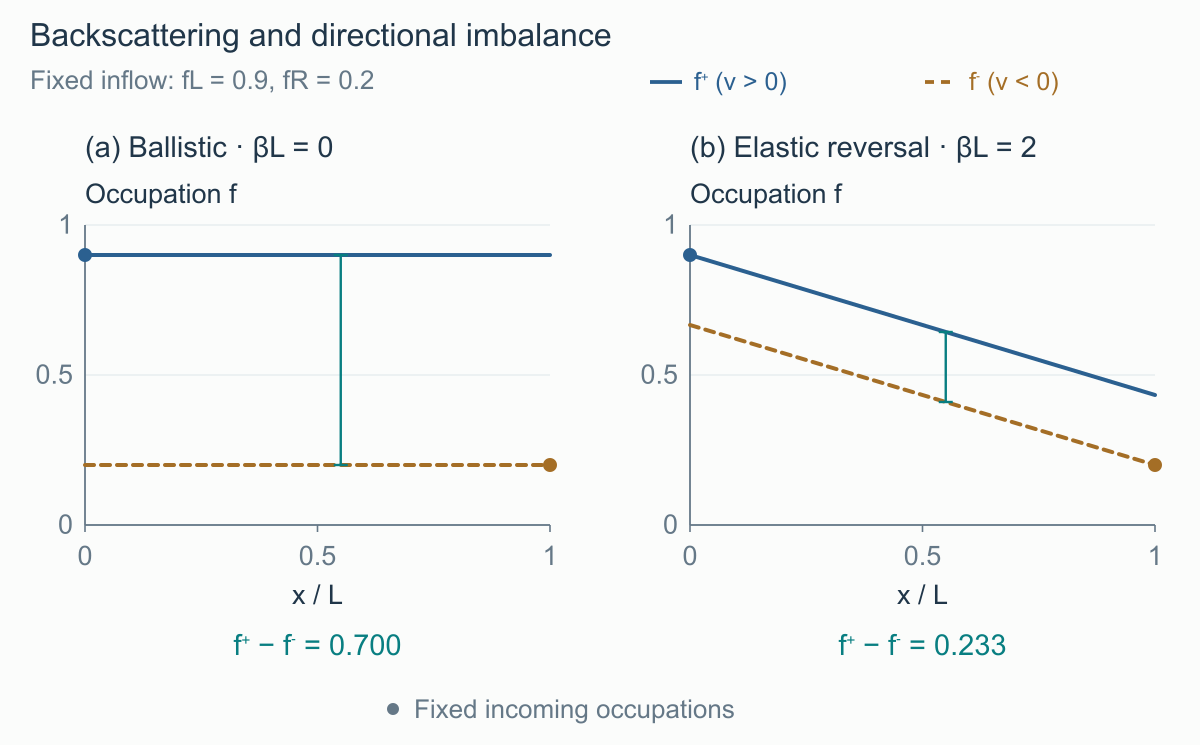

*Figure 6. Both cases use the same incoming values, 0.9 and 0.2. In the scattering case, both directional occupations vary, but their difference remains constant. The net current is reduced everywhere by the same factor, not progressively lost along the wire.*




**Is 1/β the mean free path? A factor-of-two trap**


In a homogeneous one-subband system, the unblocked reversal-rate coefficient is $r=v\beta$. In the dilute limit, where final states are almost empty, reversals form a **Poisson process**—independent events at a constant rate—with mean distance $v/r=1/\beta$. At finite occupation, Pauli blocking changes the rate of accepted individual events; that simple event-distance interpretation no longer applies automatically.

The net directional imbalance nevertheless obeys $d(f_+-f_-)/dt=-2r(f_+-f_-)$ when streaming is absent, by the elastic Pauli cancellation. Its momentum-relaxation time is $\tau_m=1/(2r)$, not $1/r$.

Thus $v\tau_m=1/(2\beta)$, while the length in Eq. (37) is $1/\beta$. Different definitions of scattering length are not interchangeable. The controls below use $\beta$ and $\gamma$ directly rather than calling either a universal mean free path.



## 14. A conservative finite-volume solver


With two open subbands there are four unknown functions, coupled by scattering. A small **finite-volume** method replaces the wire by $N_x$ cells of width $\Delta x=L/N_x$. Each cell stores an occupation for each branch.

For a right mover, the upstream value comes from the cell on its left. For a left mover, it comes from the cell on its right. This **upwind** choice follows the physical direction of information flow. For branch $a$ in cell $i$,

$$
\frac{f_{i,a}-f_{\mathrm{up},a}}{\Delta x}
=\sum_b\kappa_{ab}(f_{i,b}-f_{i,a}).
\tag{38}
$$

For $s_a=-1$, the sign of the velocity and the reversed spatial difference cancel, which is why the left-hand side has the same form. At the two inflow faces, $f_{\rm up}$ is the reservoir occupation. No outgoing boundary value is supplied.

The following teaching implementation assembles one dense linear system. It is short enough to inspect; the downloadable reference uses block elimination so that the spatial solve scales linearly with cell count at fixed number of branches.

Moving every unknown term in Eq. (38) to the left gives a diagonal coefficient $1/\Delta x+\sum_b\kappa_{ab}$, off-diagonal collision coefficients $-\kappa_{ab}$ in the same cell, and an upstream coefficient $-1/\Delta x$. A known reservoir inflow moves to the right-hand side. In the code, `laplacian` is the matrix `diag(K.sum(axis=1)) - K` that assembles collision loss minus gain.


In [7]:
def solve_shell_demo(length_nm, K, f_left, f_right, cells=24):
    branches = K.shape[0]
    assert branches % 2 == 0 and np.allclose(K, K.T)
    assert np.all(K >= 0) and np.allclose(np.diag(K), 0)
    dx = length_nm / cells
    laplacian = np.diag(K.sum(axis=1)) - K
    A = np.zeros((cells * branches, cells * branches))
    rhs = np.zeros(cells * branches)
    plus = np.arange(branches) % 2 == 0
    for i in range(cells):
        block = slice(i * branches, (i + 1) * branches)
        A[block, block] = np.eye(branches) / dx + laplacian
        for a in range(branches):
            row = i * branches + a
            upstream = i - 1 if plus[a] else i + 1
            if 0 <= upstream < cells:
                A[row, upstream * branches + a] -= 1 / dx
            else:
                rhs[row] += (f_left if plus[a] else f_right) / dx
    f = np.linalg.solve(A, rhs).reshape(cells, branches)
    # Each face uses upwind values from DIFFERENT neighboring cells.
    fp = np.vstack([np.full((1, branches // 2), f_left), f[:, plus]])
    fm = np.vstack([f[:, ~plus], np.full((1, branches // 2), f_right)])
    face_flux = np.sum(fp - fm, axis=1)  # dimensionless spectral flux
    return (np.arange(cells) + .5) * dx, f, face_flux

x_nm, f, q_faces = solve_shell_demo(100, coupling_matrix(2), .9, .2)
print("occupation range:", f.min(), f.max())
print("face-flux variation:", np.ptp(q_faces))
assert f.min() >= .2 - 1e-12 and f.max() <= .9 + 1e-12
assert np.ptp(q_faces) < 1e-11


occupation range: 0.22023121387283215 0.8797687861271674
face-flux variation: 7.66053886991358e-15


`face_flux` is $q=\sum_n(f_{n,+}^{\rm face}-f_{n,-}^{\rm face})$. Multiplying by $g_s/h$ gives electron flux per energy in SI units. At an interior face, the plus occupation comes from the cell on the left and the minus occupation from the cell on the right.

Summing Eq. (38) over branches cancels the collision terms and gives equal net flux through the left and right faces of every cell. This is an exact discrete conservation law. The same-cell quantity $\sum_{n,s}s f_{i,n,s}$ is only an approximation to a face flux; it need not be constant at finite grid spacing.

### Conservation is exact; the continuum solution is not

First-order upwinding introduces discretization error, often called **numerical diffusion** because it smears spatial variation. For one subband, the scheme above gives the exact discrete contact transmission

$$
\mathcal T_{N_x}=
\frac{1+\beta\Delta x}{1+\beta L+\beta\Delta x}
\longrightarrow\frac{1}{1+\beta L}.
\tag{39}
$$

It conserves face flux for every grid, but reaches the continuum answer only as $\Delta x\to0$. A conservation check cannot replace a convergence check.



**One cell by hand, then the finite-grid transmission**


For one subband, one cell of length $100\,\mathrm{nm}$, $\beta=0.02\,\mathrm{nm}^{-1}$, and incoming occupations 0.9 and 0.2, Eq. (38) becomes

$$
\begin{pmatrix}0.03&-0.02\\-0.02&0.03\end{pmatrix}
\begin{pmatrix}f_+\\f_-\end{pmatrix}
=\begin{pmatrix}0.009\\0.002\end{pmatrix}.
$$

Matrix coefficients and the right-hand side use $\mathrm{nm}^{-1}$. The solution is $f_+=0.62$, $f_-=0.48$. The left face has $q_L=0.9-0.48=0.42$; the right has $q_R=0.62-0.2=0.42$. However, subtracting the two values **inside** the cell gives only 0.14. A face sees populations arriving from opposite sides, so using the same-cell difference would compute the wrong discrete current.

For $N_x$ equal cells indexed from 1, subtracting the two branch equations at adjacent cells shows that $d=f_{i,+}-f_{i,-}$ is constant. The discrete boundary equations and face reconstruction give

$$
\begin{aligned}
f_L-f_R&=(1+\beta L+\beta\Delta x)d,\\
q&=(1+\beta\Delta x)d.
\end{aligned}
$$

Taking $q/(f_L-f_R)$ yields Eq. (39). Thus the exact finite-grid formula and the continuum formula describe different approximations to the same transport problem; they are not interchangeable benchmarks.


In [8]:
beta, length_nm = 0.02, 100.0
exact = 1 / (1 + beta * length_nm)
errors = []
for nx in (12, 24, 48):
    _, _, q = solve_shell_demo(length_nm, coupling_matrix(1, beta), .9, .2, nx)
    transmission = q[0] / (.9 - .2)
    dx = length_nm / nx
    discrete = (1 + beta * dx) / (1 + beta * length_nm + beta * dx)
    assert np.isclose(transmission, discrete)
    errors.append(abs(transmission - exact))
    print(nx, round(transmission, 6), round(abs(transmission - exact), 6))
assert errors[2] < errors[1] < errors[0]


12 0.368421 0.035088
24 0.351351 0.018018
48 0.342466 0.009132


[Open interactive example](https://pilkwangkim.github.io/posts/Multi-Subband-Boltzmann-Transport-From-Scratch/#lab-msbte-scattering)


Keep the total energy below the second edge, then raise it above the edge: the second pair of branches should appear only when propagating states exist. Compare zero coupling, only intra-subband reversal, and added inter-subband coupling. The sum of all subband currents must remain constant even when the individual subband currents exchange particles. A common change in every directional occupation does not itself imply a current change.

With identical coefficients and ordinary equilibrium reservoirs, symmetry makes the two modes' occupation profiles coincide in this particular model. To see redistribution directly, enable the **prescribed nonthermal mode-selective injector**. Its second-mode inflow is set independently; the default lowers it from 0.9 to 0.3, but the control also permits it to exceed the first-mode inflow. This is neither an equilibrium reservoir nor a calculation of a physical passive filter. Turning on inter-subband coupling then allows individual mode fluxes to change along the wire while their sum remains fixed.

The lab also reports a **transmission grid error** when an analytic benchmark applies. For two equally injected modes with identical coefficients, each mode has an effective reversal coefficient $\alpha=\beta+\gamma/2$: half of the inter-mode coupling connects to the opposite direction, while coupling to the identical same-direction occupation cancels. Replace $\beta$ by $\alpha$ in Eq. (39) to compare the finite-grid and continuum transmission. At $\beta=\gamma=0.04\,\mathrm{nm}^{-1}$, $L=100\,\mathrm{nm}$, and 12 cells, the grid gives 0.20 rather than $1/7$, a 40% overestimate despite conserving face flux. Increase the cell count to reduce it. This benchmark does not apply to unequal mode-selective inflows; the lab marks that case separately rather than reporting a misleading error.

## 15. Integrating energy gives a current—and a ballistic benchmark


For the uniform ballistic wire, insert Eq. (22) into Eq. (31):

$$
I_e=\frac{g_se}{h}\sum_n\int_{\epsilon_n}^{\infty}
[f_L(E)-f_R(E)]\,dE.
\tag{40}
$$

This is the unit-transmission **Landauer expression** for the same ideal channels and reservoirs. Agreement here checks state counting, spin, units, and boundary conditions. It does not show that a population-only BTE reproduces arbitrary coherent transmission through barriers.

At a common positive temperature, the integral is analytic:

$$
\begin{aligned}
I_e&=\frac{g_se k_BT}{h}\sum_n\left[
\ell\!\left(\frac{\mu_L-\epsilon_n}{k_BT}\right)
-\ell\!\left(\frac{\mu_R-\epsilon_n}{k_BT}\right)\right],\\
\ell(z)&=\ln(1+e^z).
\end{aligned}
\tag{41}
$$

To check the integral, define $A_\mu(a)=\int_a^\infty f_{\rm FD}(E;\mu,T)\,dE$. Substitution $u=(E-\mu)/(k_BT)$ gives $A_\mu(a)=k_BT\ln[1+\exp((\mu-a)/(k_BT))]$. Its derivative with respect to $a$ is $-f_{\rm FD}(a)$, and it vanishes as $a\to\infty$. Subtracting $A_{\mu_R}(\epsilon_n)$ from $A_{\mu_L}(\epsilon_n)$ gives Eq. (41).

All energies in Eq. (41) must use the same unit. The code uses eV inside the logarithms and converts the energy prefactor to joules:


In [9]:
def ballistic_current_A(edge_values_eV, mu_left_eV, mu_right_eV, T=300.0):
    thermal_eV = KB_EV * T
    a = (np.asarray(edge_values_eV) - mu_left_eV) / thermal_eV
    b = (np.asarray(edge_values_eV) - mu_right_eV) / thermal_eV
    integral_eV = thermal_eV * np.sum(
        np.logaddexp(0.0, -a) - np.logaddexp(0.0, -b)
    )
    return 2 * E_CHARGE / HPLANCK * (E_CHARGE * integral_eV)

print("three-mode I_e:", 1e6 * ballistic_current_A(edges, .150, .100), "uA")
assert ballistic_current_A(edges, .150, .150) == 0
assert np.isclose(ballistic_current_A(edges, .150, .100),
                  -ballistic_current_A(edges, .100, .150))


three-mode I_e: 7.398723010446173 uA


The two factors of $e$ have different jobs: one converts electron flux to amperes; the other converts an eV energy integral to joules. Omitting either changes the result by an enormous factor.

As $T\to0$, a fully open spin-degenerate channel contributes $I_e=(2e/h)(\mu_L-\mu_R)$ when both chemical potentials exceed its edge. Defining the energy-equivalent bias by $\mu_L-\mu_R=eV$, its small-signal conductance is $2e^2/h\simeq77.48\,\mu\mathrm S$. [NIST conductance quantum](https://physics.nist.gov/cuu/Constants/Table/allascii.txt)

For scattering, solve each energy shell and integrate its conserved $q(E)$ instead of replacing every shell by the same fitted transmission. Elasticity makes the shells independent; phonon emission and absorption would couple different energies and invalidate this independent-shell solver.

An **energy shell** here means all open branches at one common total energy. A narrow energy bin of width $\Delta E$ contributes approximately $\Delta I_e=(g_se/h)q(E)\Delta E$. With spin two, $q=0.2$ across a $1\,\mathrm{meV}$ bin gives about $15.50\,\mathrm{nA}$. This is the direct conversion from the solver's dimensionless face flux to amperes.



**Runnable example: integrate the scattering solution, not just the ballistic formula**


For the chosen energy-independent coefficients, the open-mode set and collision matrix are constant between consecutive subband edges. The equation is linear in the incoming occupations. If $u$ is the solution with left inflow 1 and right inflow 0, then $f_R\mathbf1+(f_L-f_R)u$ has the required reservoir values; $\mathbf1$ denotes the constant occupation 1 in every branch and cell. Its common part carries no net current, so $q(E)=(f_L(E)-f_R(E))q_{\rm unit}$.

This linearity is not a small-voltage approximation: no expansion in $\mu_L-\mu_R$ was used. The following code solves once per open-mode interval and integrates the Fermi occupations with midpoint bins. It retains the same three transverse modes as `edges` above.


In [10]:
def current_from_shells_A(edge_values_eV, mu_left_eV, mu_right_eV,
                          T=300.0, beta=.02, gamma=.01,
                          length_nm=100.0, cells=24, bins=128):
    thermal_eV = KB_EV * T
    upper = max(max(edge_values_eV), mu_left_eV, mu_right_eV) + 24 * thermal_eV
    boundaries = np.unique(np.r_[edge_values_eV, upper])
    integral_eV = 0.0
    for lo, hi in zip(boundaries[:-1], boundaries[1:]):
        n_open = np.count_nonzero(np.asarray(edge_values_eV) < (lo + hi) / 2)
        K = coupling_matrix(n_open, beta, gamma)
        _, _, unit_flux = solve_shell_demo(length_nm, K, 1.0, 0.0, cells)
        dE = (hi - lo) / bins
        energy = lo + (np.arange(bins) + .5) * dE
        injection = (fermi(energy, mu_left_eV, T)
                     - fermi(energy, mu_right_eV, T))
        integral_eV += unit_flux[0] * np.sum(injection) * dE
    return 2 * E_CHARGE**2 / HPLANCK * integral_eV

ballistic_exact = ballistic_current_A(edges, .150, .100)
ballistic_grid = current_from_shells_A(edges, .150, .100, beta=0, gamma=0)
scattered_grid = current_from_shells_A(edges, .150, .100)
print("I_e, ballistic / elastic model (uA):",
      1e6 * ballistic_grid, 1e6 * scattered_grid)
assert np.isclose(ballistic_grid, ballistic_exact, rtol=3e-4)
assert 0 < scattered_grid < ballistic_grid


I_e, ballistic / elastic model (uA): 7.397701845724329 2.187451852006462


The finite-bin error can be checked by increasing `bins`; spatial error is checked separately through `cells`. At low temperature, the Fermi step has width of order $k_BT$, so an energy grid must resolve that width as well as the subband thresholds. A coarse grid that works at room temperature may fail at 1 K.

For the default three-mode elastic example above, the midpoint integral gives $I_e\approx2.18745\,\mu\mathrm A$. Integrating the *same 24-cell solution* analytically in energy gives $2.18773\,\mu\mathrm A$, so the midpoint error is only about $-0.013\%$. The spatially continuous solution of this particular symmetric model instead gives $2.02991\,\mu\mathrm A$: the 24-cell spatial grid overestimates it by about 7.8%. A small flux-conservation residual or energy-integration error therefore does not establish spatial convergence.

The reference module exploits the same constant-coefficient structure to integrate each interval **analytically** by default: $\int_a^b(f_L-f_R)\,dE=A_{\mu_L}(a)-A_{\mu_L}(b)-A_{\mu_R}(a)+A_{\mu_R}(b)$. Its optional `integration="gauss"` mode additionally subdivides near each chemical potential on thermal-energy scales. If a physical model has energy-dependent scattering, $q_{\rm unit}$ must also be recomputed as energy changes; the constant-interval shortcut no longer applies. The reference's `current_a` is signed conventional charge current, so its electron-flow current is `-result["current_a"]`.





**Energy grids, threshold weights, and mode truncation**


For current, split an energy integration interval at every subband edge. Use quadrature nodes strictly inside each interval, not exactly on a threshold. In a numerical integration, also resolve the contact steps near $\mu_L,\mu_R$ on the $k_BT$ scale. The reference's optional Gauss–Legendre calculation does this before placing quadrature nodes; raising the node count tests integration error. Its default analytic interval calculation has no quadrature error, but still has a finite upper cutoff, a spatial grid, and a retained-mode truncation.

For density, the $1/v$ factor needs additional care. Near edge $\epsilon_n$, set $E=\epsilon_n+u^2$. Then $dE=2u\,du$ cancels the $1/u$ singularity. Alternatively integrate density in $k$, whose state-counting measure is nonsingular.

A finite upper cutoff must also be checked. For positive-temperature reservoir distributions, the unintegrated high-energy occupation decreases exponentially. Move the cutoff upward until the result is stable; “twenty thermal energies above the largest chemical potential” is a useful trial cutoff, not a universal proof for a driven inelastic distribution.

Finally, a mode is not irrelevant merely because its edge lies above $\mu$: finite-temperature occupation has a tail. Add transverse modes until both density and current are stable. The three-mode code above deliberately computes a three-mode example, not an automatically converged full-wire current.



## 16. What a trustworthy calculation should pass


The model and its discretization have different obligations. These tests separate them:

| Test | Required result | What it catches |
| :--- | :--- | :--- |
| Confinement scaling | Scaling both widths by 2 scales confinement energies by 1/4 | Geometry and unit errors |
| Equal contacts | Constant Fermi occupation; zero net current | Wrong inflow or collision balance |
| Elastic exchange | Sum of DOS-weighted collision changes is zero | Confusing occupation with particle count |
| Single subband | Approach Eq. (36) and Eq. (37) with grid refinement | Conserving but inaccurate transport |
| Every cell face | Same summed electron flux at stationarity | Artificial particle sources or sinks |
| Occupation bounds | Stay between the minimum and maximum of all prescribed inflow occupations | Sign or assembly errors |
| Ballistic energy integral | Match Eq. (41) | Spin, eV/J conversion, energy quadrature |
| More cells, energies, modes | Stable observables within a stated tolerance | False convergence in only one direction |


The [reference Python file](https://pilkwangkim.github.io/assets/code/multi-subband-bte.py) returns diagnostic arrays rather than only a final current. Its checks include the discrete one-subband formula as well as the continuum limit. A **residual** is the mismatch left when the computed values are substituted into the discretized equations. Residuals, flux continuity, and an analytic benchmark answer different questions; a small linear-system residual alone does not validate the physics.

The notebook executes the teaching snippets in order with Python 3.9+ and NumPy. The browser examples run fixed, bounded models; full code editing belongs in the notebook or downloaded module.

## 17. How a device model closes the electrostatic loop


So far the wire geometry and subband edges were prescribed. In a transistor, the electrons themselves change the electrostatic potential, which changes their subbands and occupations. **Self-consistency** means finding a potential and electron distribution that agree with each other.

Let $N_D^+$ be the number density of a fixed positive background, such as ionized donor atoms that have released electrons. If each background particle carries charge $+e$ and electrons provide the only other charge, Poisson's equation is

$$
\nabla\cdot(\varepsilon\nabla\varphi)
=-\rho=e(n_{3D}-N_D^+).
\tag{42}
$$

$\varepsilon$ is the material permittivity, which describes its electric response, $\rho=e(N_D^+-n_{3D})$ is charge density, and $\varphi$ is electric potential. Poisson's equation relates the spatial variation of that potential to the charge that produces it. The positive sign of the electron term on the right is a consequence of the minus sign in Poisson's equation, not a positive electron charge.

For a trial $\varphi$, the transverse Hamiltonian includes the conduction-band confinement profile and $-e\varphi$. Solving it at each longitudinal slice produces $\epsilon_n(x)$ and $\phi_n(x;y,z)$. The MS-BTE then supplies $N_n(x)$, and Eq. (19) reconstructs the charge density used by Poisson's equation. Repeat until the potential, density, and terminal current meet tolerances. Mixing successive potential updates is one way to stabilize a simple iteration.

A simple mixing update replaces a trial potential by a weighted average of the old potential and the newly solved one. Electrostatic boundary data at gates and contacts are also required: Poisson's equation without boundary conditions does not select a unique device potential. The transverse wavefunctions must be normalized at every slice so that the line densities reconstruct the correct volume charge.

The coupling of Schrödinger, Poisson, and subband transport equations is the device-model architecture studied by [Ben Abdallah et al.](https://doi.org/10.1016/j.jcp.2009.06.001). Realistic multi-valley implementations also compute scattering from the material model and transverse states. [Caruso et al.](https://doi.org/10.3390/electronics10202472)

The implementation here holds the subband edges fixed. It therefore does not compute gate-controlled channel charge, source/drain depletion, or a self-consistent transistor $I$–$V$ curve. Adding a Poisson equation without consistent geometry, contact conditions, and material parameters would not supply those predictions automatically.



**From a scalar effective mass to valleys and nonparabolic bands**


A **valley** is a distinct minimum of the crystal's conduction-band dispersion. Different valleys can have different directional effective masses and confinement energies. A multi-valley model adds a valley label to the subband index and includes allowed inter-valley transitions.

**Nonparabolicity** means the dispersion is no longer exactly quadratic in $k$. The group velocity must then still be computed from $v=\partial_kE/\hbar$, rather than keeping $\hbar k/m^*$ by habit. State-counting weights, transition thresholds, and energy-to-momentum conversion must change consistently. A more complicated band model is useful only if its parameters and corresponding scattering model are supplied together.



## 18. Computational savings and the choice of transport model


### When does mode reduction actually save work?

The $N_xN_kN_s$ occupation count is attractive only if a modest $N_s$ resolves the observables of interest. When temperature, injection energy, or bias opens many modes, that advantage can shrink. More modes may also be needed to describe sharp geometric variations or coupling through modes that are not themselves strongly occupied. A high subband edge is not a universal license to delete that mode.

There is work outside the occupation array: transverse eigenproblems at longitudinal slices, scattering overlaps, electrostatics, and the transport solve itself. There are potentially $N_s^2$ ordered mode pairs, but that is a **pair count**, not a universal time-complexity formula. Elasticity, allowed momentum transfers, material selection rules, sparsity, quadrature, and the numerical algorithm determine the actual collision cost. Keeping a full mode-coherence matrix would itself introduce two mode indices rather than the single index of scalar populations.

Increase the retained mode set and check density, current, and transition pathways, not just the occupancy of the last retained mode. In a quantum calculation, weakly occupied or closed modes can affect propagation through virtual coupling; in a kinetic model, additional modes may open scattering pathways. A convergence check applies to the equations actually solved. It cannot validate the omission of coherence by construction. Real-space versus finite-mode NEGF comparisons likewise use current convergence to assess the mode truncation. [Martinez et al.](https://eprints.gla.ac.uk/41426/)

### Other representations and solution methods

Three choices should not be conflated: **physical model**, **state representation**, and **numerical solver**.

| Choice | What changes | Limits / checks |
| :--- | :--- | :--- |
| Grid / basis BTE | Discretize the distribution or expand it in basis functions | Quantum confinement must still enter the states/energies |
| Monte Carlo BTE or MS-BTE | Sample trajectories and collision events instead of storing every distribution value | Sampling does not restore omitted coherence; noise needs convergence checks |
| Moment or drift–diffusion model | Retain quantities such as density and mean energy, with closure assumptions | A few moments need not resolve a strongly nonthermal distribution |
| Real-space quantum transport | Keep spatial quantum amplitudes and correlations, for example in NEGF | More detail does not remove the need for a valid Hamiltonian and scattering model |
| Coupled mode-space quantum transport | Express quantum equations in transverse modes and retain their coherent coupling | Using modes does not require a Boltzmann or diagonal-population approximation |


For bulk BTE, **spherical-harmonics expansion** replaces angular dependence in momentum space by coefficients of known angular functions; increasing the retained expansion order checks that angular approximation. Monte Carlo, such expansions, and adaptive grids are alternatives to a huge direct tensor grid, not evidence that BTE itself cannot be solved. [Rupp et al.](https://iue.tuwien.ac.at/pdf/ib_2011/BC2012_Rupp_2.pdf)

For confinement with important longitudinal interference or tunneling, quantum transport may be required. **NEGF** works with Green functions and correlation functions that encode propagation and occupation in an open quantum system. It can be implemented in real space or in coupled mode space, and can include scattering approximations. Mode-space NEGF demonstrates why “using subbands” and “discarding quantum coherence” are separate decisions. [Martinez et al.](https://eprints.gla.ac.uk/41426/) The [NEGF tutorial](https://pilkwangkim.github.io/posts/From-Closed-to-Open-Quantum-Transport-with-NEGF/) develops its Hamiltonian and contact description.

A **ballistic** channel has negligible scattering over its length. Ballistic does not mean coherent or incoherent by definition: collisionless scalar BTE and coherent ballistic NEGF retain different information. The local, longitudinal semiclassical model developed here does not calculate generic under-barrier tunneling, interference fringes, or coherent conversion between modes. That is not a theorem that every population equation in every basis excludes every tunneling effect: quantum eigenstates can already contain barrier penetration and spatial hybridization. The precise omission is coherence between the states of the chosen population model. [Milovanović, Sec. 4.2](https://www.iue.tuwien.ac.at/phd/milovanovic/diss_htmlse9.html)

**Elastic** means total electron energy is conserved; it does not mean phase is lost. Static disorder can scatter coherently. Replacing amplitudes by transition rates discards interference as a modeling step; increasing $\beta$ alone does not justify it. In long phase-coherent disordered wires, interference can strongly suppress transport through **localization**, absent from this rate model. [Beenakker](https://doi.org/10.1103/RevModPhys.69.731)

MS-BTE is therefore useful when confinement needs quantum states, many collisions need a kinetic treatment, and longitudinal phase coherence is not essential to the target observable. It is neither the only confined-system method nor a cost-free exact version of full quantum transport. Its reductions are valuable when their assumptions and convergence are controlled.

## 19. Exercises: reduction, states, and conservation



[Open interactive example](https://pilkwangkim.github.io/posts/Multi-Subband-Boltzmann-Transport-From-Scratch/#lab-msbte-quiz)




**Warm-up: distinguish motion, approximation, and truncation**


1. In the free-flight example, the occupation at a fixed $x$ changes. Does that imply a collision occurred? What would remain unchanged if you followed the moving peak?
2. Compare $\rho\to U^\dagger\rho U$, $M\to D$, and $D\to PDP$ in Figure 3. Which is only a representation change, which discards coherence, and which discards a state? Why would renormalizing $PDP$ hide useful information?
3. A program keeps every transverse mode but solves only scalar populations. Has it therefore recovered full quantum transport? Conversely, does using a mode basis force a program to solve BTE rather than NEGF?

**Answers.** **1.** No: streaming alone moves the profile. Its peak occupation stays 0.9. **2.** The complete unitary rotation preserves the state; taking the diagonal discards coherence in that basis; projection omits a state. Its trace 0.9 exposes the omitted probability. **3.** No in both cases. More modes do not restore discarded coherence, and mode-space quantum equations can retain coherent coupling.



### 1. Add a phonon before changing subbands

Use the wire in Figure 5. An electron has total energy $100\,\mathrm{meV}$ in subband 1. Can a static elastic perturbation move it into subband 2, whose edge is about $110\,\mathrm{meV}$? If it absorbs a $20\,\mathrm{meV}$ phonon first, what becomes possible?



**Answer**


At $100\,\mathrm{meV}$, subband 2 has no propagating final state because its required longitudinal kinetic energy would be negative. Absorbing a $20\,\mathrm{meV}$ phonon raises the electron's total energy to $120\,\mathrm{meV}$; a final state in subband 2 is then energetically allowed with about $10\,\mathrm{meV}$ of longitudinal kinetic energy. Energetically allowed does not mean guaranteed: the transition matrix element and phonon population still determine the rate.



### 2. Compare density when the speeds differ

At the same total energy, suppose $v_1=2v_2$ and all four branches have occupation 0.4. Compare the two subbands' density contributions in a small common energy interval. What is the net current?



**Answer**


Each subband's density contribution is proportional to $(f_++f_-)/v_n$, so subband 2 contributes twice as much density as subband 1. The current is zero because each mode has equal plus and minus occupations. Equal occupation, equal density, and equal current are three different conditions.



### 3. A constant current on a coarse grid: is the answer accurate?

For $\beta L=2$ and $N_x=10$, calculate Eq. (39) and compare it with Eq. (37). Explain why exact face-flux conservation does not resolve the difference.



**Answer**


$\beta\Delta x=0.2$, so $\mathcal T_{10}=1.2/3.2=0.375$. The continuum value is $1/3\simeq0.3333$. The finite grid overestimates transmission by 12.5% relative to the continuum answer, even though its current is exactly conserved. Refining the spatial approximation addresses this error; tightening the linear-system tolerance does not.



### 4. Coding test: implement a conservative collision update

**Input.** A one-dimensional NumPy array `f` of occupations, positive speeds `v`, and a symmetric nonnegative matrix `K` with zero diagonal. The states are branches at one common energy. `K` is in inverse length, and `v` uses the matching length/time unit.

**Output.** An array `C` of occupation changes per time, according to Eq. (32). Do not normalize `f` to sum to one. Do not normalize the rows of `K`; that changes the physical model.

For `f=[0.8,0.2]`, `v=[2,2]`, and `K=[[0,0.1],[0.1,0]]`, the answer is `[-0.12,0.12]`. With unequal speeds, the **weighted** sum `sum(C/v)` must vanish, not necessarily `sum(C)`.


In [11]:
def elastic_collision(f, v, K):
    # Return a new array. Do not mutate any input.
    raise NotImplementedError("Implement the gain-minus-loss occupation change")

def check_collision(candidate):
    K = coupling_matrix(2, beta=.03, gamma=.02)
    v = np.array([2., 2., 1., 1.])
    for f0 in (np.array([.9, .1, .3, .3]),
               np.array([0., 1., .2, .8]), np.full(4, .37)):
        original_f, original_v, original_K = f0.copy(), v.copy(), K.copy()
        expected = original_v * np.sum(
            original_K * (original_f[None, :] - original_f[:, None]), axis=1)
        C = np.asarray(candidate(f0, v, K))
        assert np.array_equal(f0, original_f), "f was mutated"
        assert np.array_equal(v, original_v), "v was mutated"
        assert np.array_equal(K, original_K), "K was mutated"
        assert not any(np.shares_memory(C, a) for a in (f0, v, K)), "Return a new array"
        assert C.shape == original_f.shape and np.allclose(C, expected)
        assert abs(np.sum(C / original_v)) < 1e-12
        # A sufficiently small explicit step remains an occupation in [0,1].
        rate = np.max(original_v * original_K.sum(axis=1))
        updated = original_f + (0.5 / rate) * C
        assert np.all(updated >= -1e-12) and np.all(updated <= 1 + 1e-12)
    return "3 cases passed"

# After implementing your function, uncomment:
# print(check_collision(elastic_collision))


**Reference solution and why the time step matters**


In [12]:
def elastic_collision_reference(f, v, K):
    gain = K @ f
    loss = K.sum(axis=1) * f
    return v * (gain - loss)

print(check_collision(elastic_collision_reference))


3 cases passed


The continuous collision equation preserves $0\le f\le1$: at $f_a=0$ its derivative is nonnegative, and at $f_a=1$ it is nonpositive. An **explicit Euler update** takes one step as $f^{\rm new}=f+\Delta t\,C[f]$ and needs a sufficiently small $\Delta t$. If $\Delta t\,v_a\sum_b\kappa_{ab}\le1$ for every branch, the new occupation is a **convex combination** of the old occupations: an average with nonnegative weights summing to one. It therefore remains within their bounds. A huge time step can violate positivity even when the collision formula itself is correct.

This test checks the collision operator, not the complete device solver. Contacts, streaming, energy integration, and material validity have their own tests.



The connection is now complete: BTE balances motion and collisions; confinement supplies transverse quantum modes; a longitudinal kinetic approximation and population closure lead to MS-BTE; a converged finite mode set makes it tractable. Contact inflow and state counting then turn the solved occupations into density and current. Each step has its own assumptions and checks.

## References

- K. Rupp, T. Grasser, and A. Jüngel, [“Deterministic Numerical Solution of the Boltzmann Transport Equation”](https://iue.tuwien.ac.at/pdf/ib_2011/BC2012_Rupp_2.pdf). Six-dimensional phase space, Monte Carlo versus deterministic angular expansions, and memory reduction. The storage numbers above are illustrative counts, not reported benchmarks from this paper.
- N. Ben Abdallah and F. Méhats, [“Semiclassical analysis of the Schrödinger equation with a partially confining potential”](https://doi.org/10.1016/j.matpur.2004.10.004), *Journal de Mathématiques Pures et Appliquées* **84**, 580–614 (2005). DOI: 10.1016/j.matpur.2004.10.004. A partial semiclassical limit in the unconfined direction; collisionless transport rather than a derivation of all device scattering models.
- G. Milovanović, [*Numerical Modeling of Quantum Cascade Lasers*, Sec. 4.2](https://www.iue.tuwien.ac.at/phd/milovanovic/diss_htmlse9.html), TU Wien doctoral thesis (2011). Subband kinetics, Markov and diagonal approximations, and the distinction between quantum structure already present in eigenstates and coherence between states.
- M. V. Fischetti, S. E. Laux, and A. Kumar, [“Simulation of Quantum Transport in Small Semiconductor Devices”](https://in4.iue.tuwien.ac.at/pdfs/sispad2005/1562014.pdf), *SISPAD 2005*, pp. 19–22, Sec. II. Initial/injected states and diagonal closure; Markov and mean-field assumptions are separate steps.
- A. Martinez, A. R. Brown, A. Asenov, and N. Seoane, [“A comparison between a fully-3D real-space versus coupled mode-space NEGF in the study of variability in gate-all-around Si nanowire MOSFET”](https://eprints.gla.ac.uk/41426/), *SISPAD 2009*, pp. 194–197. Mode-space quantum transport, finite-mode accuracy, and current-based convergence comparisons.
- ABINIT documentation, [“fold2bloch”](https://docs.abinit.org/tutorial/fold2bloch/). Brillouin-zone folding associated with supercell representations; distinct from hard-wall transverse quantization.
- N. Ben Abdallah, M. J. Cáceres, J. A. Carrillo, and F. Vecil, [“A deterministic solver for a hybrid quantum-classical transport model in nanoMOSFETs”](https://doi.org/10.1016/j.jcp.2009.06.001), *Journal of Computational Physics* **228**, 6553–6571 (2009). DOI: 10.1016/j.jcp.2009.06.001. Coupled transverse Schrödinger–Poisson and longitudinal subband transport; deterministic numerical methods.
- M. Noei, T. Linn, and C. Jungemann, [“A numerical approach to quasi-ballistic transport and plasma oscillations in junctionless nanowire transistors”](https://link.springer.com/article/10.1007/s10825-020-01488-4), *Journal of Computational Electronics* **19**, 975–986 (2020). DOI: 10.1007/s10825-020-01488-4. Open-access wire MS-BTE, contact treatment, and phase-space discretization. Its chosen statistics/scattering approximations are not identical to every model above.
- E. Caruso et al., [“Modeling Nanoscale III–V Channel MOSFETs with the Self-Consistent Multi-Valley/Multi-Subband Monte Carlo Approach”](https://doi.org/10.3390/electronics10202472), *Electronics* **10**, 2472 (2021). DOI: 10.3390/electronics10202472. Realistic model extensions, material scattering, and explicitly added longitudinal quantum corrections.
- G. Baccarani, E. Gnani, A. Gnudi, and S. Reggiani, [“Quasi-Ballistic Transport in Nanowire Field-Effect Transistors”](https://in4.iue.tuwien.ac.at/pdfs/sispad2008/pdfs/4648223.pdf), *SISPAD 2008*, pp. 5–8. Elastic one-dimensional BTE solutions and the distinction between angular redistribution and energy relaxation.
- MIT, [8.321 Quantum Theory I, Lecture 26](https://ocw.mit.edu/courses/8-321-quantum-theory-i-fall-2017/81f6e90a6cdd311ca5f3afb32e9da1f2_MIT8_321F17_lec26.pdf) (2017). Transition rates from time-dependent perturbation theory.
- MIT, [8.333 Statistical Mechanics I, Fermi–Dirac statistics notes](https://www.mit.edu/~jgt/Content-Web/Teaching/8333/8333%202025%20Lecture%2028.pdf) (2025). Equilibrium occupation and chemical potential.
- NIST, [CODATA conductance quantum](https://physics.nist.gov/cuu/Constants/Table/allascii.txt). Value of $2e^2/h$.
- Purdue University, [NEMO: Realistic Dispersion Relationships](https://engineering.purdue.edu/gekcogrp/software-projects/nemo/dispersion.php). Parabolic effective-mass approximation and its limits.
- D. Xiao, M.-C. Chang, and Q. Niu, [“Berry phase effects on electronic properties”](https://doi.org/10.1103/RevModPhys.82.1959), *Reviews of Modern Physics* **82**, 1959–2007 (2010), Secs. IV–V. Wavepacket construction and semiclassical scale assumptions; only the scalar parabolic limit is used here.
- C. W. J. Beenakker, [“Random-matrix theory of quantum transport”](https://doi.org/10.1103/RevModPhys.69.731), *Reviews of Modern Physics* **69**, 731–808 (1997). Phase-coherent disordered wires, phase breaking, and localization.
